<div style="background-color:blue"><h1 style="color:black;text-align:center">PROJET DE DEEP-LEARNING: Prédiction des tendances boursières</h1></div>

<div style="color:black;background-color: whitesmoke; padding: 5px; border-radius: 5px;">
<h3 style="color:black;text-align:center">NOMS DES PARTICIPANTS</h3>
</div>

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(0, 0, 0, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: rgba(151, 158, 217, 1);
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>NOMS</u><br/></td>
                <td><u>PRENOMS</u><br/></td>
                <td><u>MATRICULE</u><br/></td>
            </tr>
            <tr>
                <td><b>NGUETSA VOFO</b><br/></td>
                <td>Doriane Vianny<br/></td>
                <td><b>22P578</b><br/></td>
            </tr>
            <tr>
                <td><b>NGUEMO DONFACK</b><br/></td>
                <td>Daniella<br/></td>
                <td><b>22P307</b><br/></td>
            </tr>
            <tr>
                <td><b>NOUNDJEU KENGNI</b><br/></td>
                <td>Théophane<br/></td>
                <td><b>22P263</b><br/></td>
            </tr>
            <tr>
                <td><b>NJI MOUICHE</b><br/></td>
                <td>Adamou Romaric<br/></td>
                <td><b>24P809</b><br/></td>
            </tr>
            <tr>
                <td><b>NOUNDOU</b><br/></td>
                <td>Astrid<br/></td>
                <td><b>21P304</b><br/></td>
            </tr>
            <tr>
                <td><b>NOUNGUEP KOUKAM</b><br/></td>
                <td>Stéphane<br/></td>
                <td><b>22P518</b><br/></td>
            </tr>
            
           
          
         

        </table>
</div>

<h2 style="color: cyan; text-align: center">DÉFINITION DES TERMES CLÉS </h2>

* **RNN**(Réseaux de neurones récurrents): Réseau de neurones conçu pour traiter des données séquentielles en conservant une mémoire des entrées précédentes.</br>
Le principe fondamental d'un RNN est l'utilisation des boucles de rétro-action. Contrairement aux réseaux *feedfoward*, l'information peut circuler de manière cyclique, permettant ainsoi au réseau de traiter des séquences de longueurs variables.</br></br>
La formule de base est:
$$h_t = tanh(W_h h_{t−1} + W_x x_t +b)$$
Où:
* * $W_h$ et $W_x$ sont les matrices de poids
* * b est le vecteur biais
* * $tanh$ est notre fonction d'activation
Le principal défi des RNN est le problème de la disparition du gradient (*vanishing gradient*), ce qui limite leur capacité à retenir des informations sur de longues périodes. Le **LSTM** a été introduit pour pallier ce manque


* **LSTM**(Long Short-Term Memory):C'est un type de spécial de RNN conçu pour résoudre le problème du gradient qui disparaît (vanishing gradient). Sa formule est:
$$\begin{cases}
f_t = \sigma(W_f [h_{t−1},x_t] + b_f)\qquad (forget)\\
i_t = \sigma(W_i[h_{t−1},x_t] + b_i)\qquad (input)\\
\tilde{C}_t =tanh(W_C[h_{t−1},x_t]+b_C)\qquad (candidate)\\
C_t =f_t \odot C_{t−1} +i_t \odot \tilde{C}_t\qquad (cell \ update)\\
o_t = \sigma(W_o[h_{t−1},x_t] + b_o)\qquad (output)\\
h_t = o_t \odot tanh(C_t)\qquad (hidden \ state)
\end{cases}$$

* **MÉCANISME D'ATTENTION**: Un mécanisme qui permet à un modèle de focaliser ses ressources computationnelles sur les parties les plus importantes des données d'entrée. Sa formule théorique est:
$$\begin{cases}
e_t = v^⊤ tanh(W_1h_t +W_2 s_{t−1})\qquad(score)\\
\alpha_t=\frac{exp(e_t)}{\sum_{k=1}^{T} exp(e_k)}\qquad (softmax)\\
c_t=\sum_{t=1}^{T} \alpha_t h_t \qquad (contexte)

\end{cases}$$

* **VALIDATION CROISÉE**: Technique d'évaluation qui divise les données en plusieurs sous-ensembles pour entraîner et tester le modèle de manière itérative.</br>
Dans le cas des series temporelles, on a pas de *shuffle* : les *folds* sont successifs dans le temps pour éviter le *data leakage*. </br> On utilise plutôt une **Validation Croisée par Fenêtre Glissante**(*ou Time Series Split*):  Cette méthode consiste à entraîner le modèle sur une période passée et à le valider sur une période future immédiate, en augmentant progressivement la fenêtre d’entraînement.

<h2 style="color: cyan; text-align: center">IMPORTATION DES BIBLIOTHÈQUES </h2>

Nous importons les bibliothèques qui serons utilisées dans la suite

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

#pour la validation croisée
from sklearn.model_selection import TimeSeriesSplit

# pour la stationarité
from datetime import datetime, timedelta
from statsmodels.tsa.stattools import adfuller 
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

# pour l'apprentissage profond
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Layer
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout, BatchNormalization, Input, Multiply, Permute, Activation, RepeatVector, Lambda
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


#Pour le déploiement du modèle optimal
from flask import Flask, request, jsonify
import numpy as np
import joblib
import json
from tensorflow.keras.models import load_model


import warnings
import yfinance as yf
warnings.filterwarnings("ignore")
# configuartion des graphiques 
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('Set2')

<h2 style="color: cyan; text-align: center"> chargement du jeu de données: Base de données de GOOGLE depuis yfinance </h2>

Nous importons les données historiques sur les prix des actions de GOOGLE à partir de la bibliothèque ***yfinance***

In [3]:
#choisir l'actif à analyser 
TICKER = 'GOOGL'
# Période de télégergement 
START_DATE = '2018-01-01'
END_DATE = '2025-12-18'
print(f"téléchargement des données {TICKER}...")
print(F" Période :{START_DATE} à {END_DATE}")

#téléchargement des données 
df = yf.download(TICKER, start = START_DATE, end = END_DATE, progress = False)
print(f"\n téléchargement reussi!")
print(f"{len(df)} jours de donnees")
print(f"colonnes:{list(df.columns)}")

téléchargement des données GOOGL...
 Période :2018-01-01 à 2025-12-18

 téléchargement reussi!
2002 jours de donnees
colonnes:[('Close', 'GOOGL'), ('High', 'GOOGL'), ('Low', 'GOOGL'), ('Open', 'GOOGL'), ('Volume', 'GOOGL')]


Regardons les 5 premières lignes de notre base de données

In [4]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL
Date,,,,,
2018-01-02,53.258095,53.395556,52.256167,52.256167,31766000
2018-01-03,54.166729,54.394012,53.269013,53.293823,31318000
2018-01-04,54.377140,54.790021,54.302706,54.443143,26052000
2018-01-05,55.098194,55.261462,54.676878,54.758760,30250000
2018-01-08,55.292721,55.538366,55.083801,55.133425,24644000


<h3 style="color: lightgreen; text-align: center">Description des variables </h3>

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2002 entries, 2018-01-02 to 2025-12-17
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, GOOGL)   2002 non-null   float64
 1   (High, GOOGL)    2002 non-null   float64
 2   (Low, GOOGL)     2002 non-null   float64
 3   (Open, GOOGL)    2002 non-null   float64
 4   (Volume, GOOGL)  2002 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 93.8 KB


<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>VARIABLE</u><br/></td>
                <td><u>DESCRIPTION</u><br/></td>
                <td><u>TYPE</u><br/></td>
            </tr>
            <tr>
                <td><b>Price Close</b><br/></td>
                <td>prix de l'action en fin de journée<br/></td>
                <td>float<br/></td>
            </tr>
            <tr>
                <td><b>Price High</b><br/></td>
                <td>le plus haut prix atteint par l'action durant la journée<br/></td>
                <td>float<br/></td>
            </tr>
            <tr>
                <td><b>Price High</b><br/></td>
                <td>le plus haut prix atteint par l'action durant la journée<br/></td>
                <td>float<br/></td>
            </tr>
            <tr>
                <td><b>Price Low</b><br/></td>
                <td>le plus bas prix atteint par l'action durant la journée<br/></td>
                <td>float<br/></td>
            </tr>
            <tr>
                <td><b>Price Open</b><br/></td>
                <td>prix de l'action en début de journée<br/></td>
                <td>float<br/></td>
            </tr>
            <tr>
                <td><b>Volume</b><br/></td>
                <td>quantité d'actions échangée durant la journée(achetée ou vendue)<br/></td>
                <td>int<br/></td>
            </tr>
        </table>
</div>

<h2 style="color: cyan; text-align: center">PRÉTRAITEMENT ET PRÉPARATION DES DONNÉES </h2>

<h3 style="color: lightgreen; text-align: center">gestion des valeurs manquantes,des formats, des doublons et des valeurs aberrantes</h3>

In [6]:
#regardons les nombre de valeurs manquantes dans notre base de données
df.isnull().sum() * 100 / len(df)

Price   Ticker
Close   GOOGL     0.0
High    GOOGL     0.0
Low     GOOGL     0.0
Open    GOOGL     0.0
Volume  GOOGL     0.0
dtype: float64

On constate qu'il n'ya aucune valeur manquante pour toutes nos variables

In [7]:
#Nombre de doublons
df.duplicated().sum()

np.int64(0)

Nous n'avons également aucun doublon dans notre base de données

In [8]:
#vérifions les formats
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2002 entries, 2018-01-02 to 2025-12-17
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, GOOGL)   2002 non-null   float64
 1   (High, GOOGL)    2002 non-null   float64
 2   (Low, GOOGL)     2002 non-null   float64
 3   (Open, GOOGL)    2002 non-null   float64
 4   (Volume, GOOGL)  2002 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 93.8 KB


Tous les formats sont corrects, rien à modifier

In [9]:
#Pour détecter les valeurs abérrantes, nous allons utiliser la methode IQR 
num_cols=df.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols=df.select_dtypes(include=['object','category']).columns.tolist()
print("nombre d'individus aux valeurs aberrantes par variable:\n")
print("nombre de valeurs abérrantes<------>pourcentage")
for col in num_cols:
    Q1=df[col].quantile(0.25)#premier quartile
    Q3=df[col].quantile(0.75)#troisieme quartile
    IQR=Q3-Q1#ecart inter-quatile
    val_min=Q1-1.5*IQR#la valeur minimale des valeurs non-aberrantes
    val_max=Q3+1.5*IQR#la valeur maximale des valeurs non-aberrantes
    outliers=df[(df[col]<val_min)|(df[col]>val_max)].index#on recupere les indices des valeurs aberrantes
    
    print(f"{col}:{len(outliers)}<------>{100*len(outliers)/len(df):.2f}%")

nombre d'individus aux valeurs aberrantes par variable:

nombre de valeurs abérrantes<------>pourcentage
('Close', 'GOOGL'):37<------>1.85%
('High', 'GOOGL'):37<------>1.85%
('Low', 'GOOGL'):37<------>1.85%
('Open', 'GOOGL'):37<------>1.85%
('Volume', 'GOOGL'):118<------>5.89%


Notre base de données présente des données abérrants. Bien que les pourcentagges ne soients pas très forts, nous devons appliquer les méthodes de gestion de valeurs aberrantes que nous jugeons pas très biaisées: La <span style ="color:orange;">winsorisation</span>:<br>

On va tracer les boxplot pour savoir comment prendre nos limites pour la winsorisation

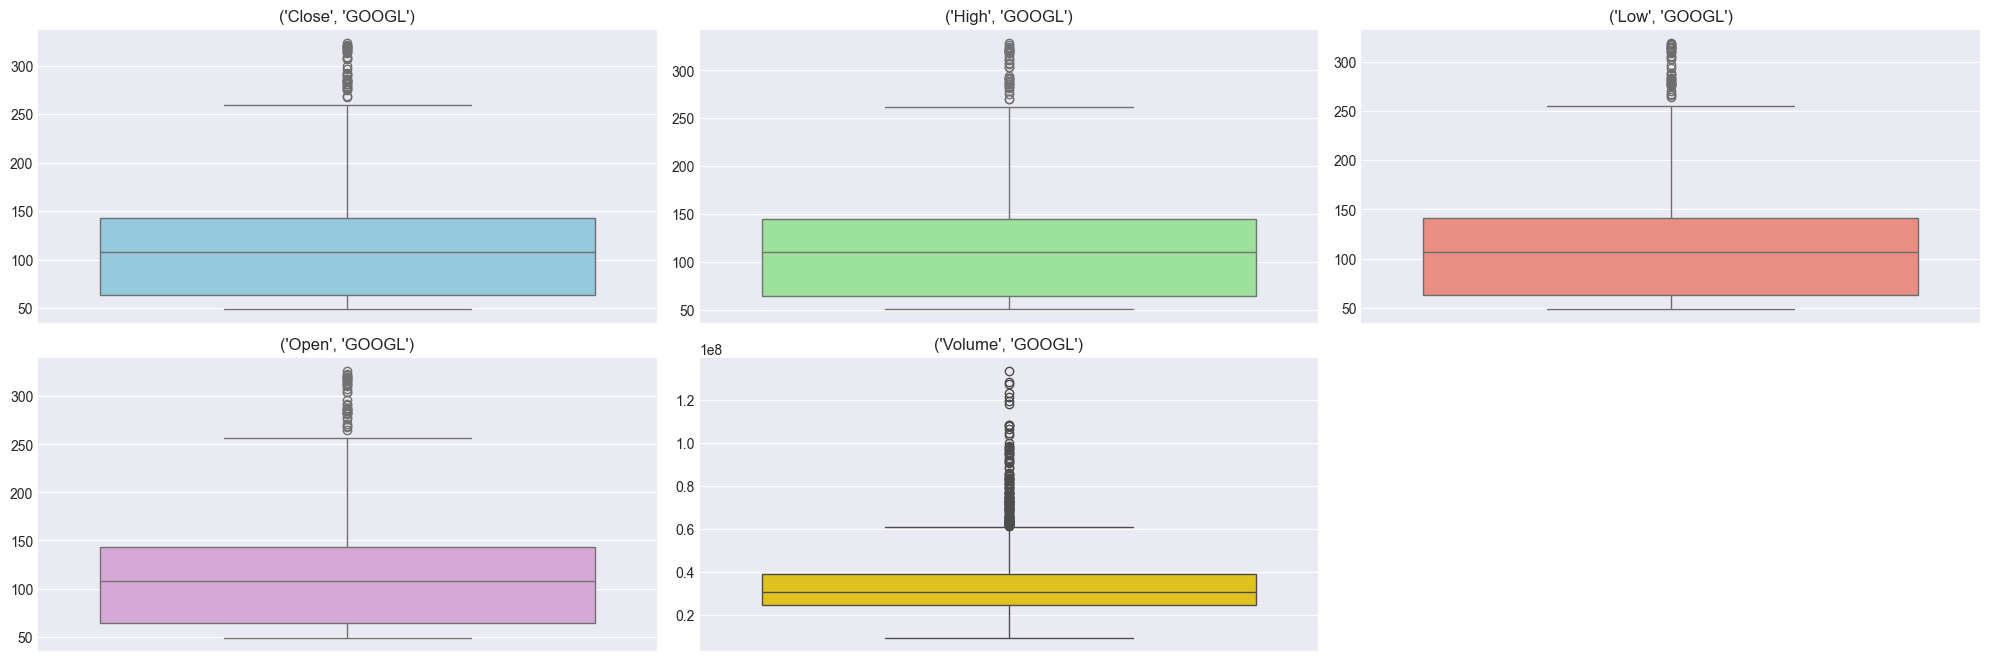

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(20, 10))  # 2 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise']

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=colors[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('')

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

On constate que les valeurs abérrantes sont uniquement celles extrêmement grandes. On va donc faire une winsorisation déséquilibrée qui va plus affecter les grandes valeurs sans impacter les plus petites:

In [11]:
df1=df.copy()#on conserve notre base de données initiale


In [12]:
df=df1.copy()
from scipy.stats.mstats import winsorize
for i in [0,1,2,3]:
    col=num_cols[i]
    df[col]=winsorize(df[col], limits=[0.00,0.02])#on fixe les limites a 0%-98% pour les 4 premières variables
    
col=num_cols[4]
df[col]=winsorize(df[col], limits=[0.00,0.06])#on fixe les limites a 0%-94% pour la dernière variable


print("nombre d'individus aux valeurs aberrantes par variable:\n")

for col in num_cols:
    Q1=df[col].quantile(0.25)#premier quartile
    Q3=df[col].quantile(0.75)#troisieme quartile
    IQR=Q3-Q1#ecart inter-quatile
    val_min=Q1-1.5*IQR#la valeur minimale des valeurs non-aberrantes
    val_max=Q3+1.5*IQR#la valeur maximale des valeurs non-aberrantes
    outliers=df[(df[col]<val_min)|(df[col]>val_max)].index#on recupere les indices des valeurs aberrantes
    print(f"{col}:{len(outliers)} <------> {100*len(outliers)/len(df):.2f}%")

nombre d'individus aux valeurs aberrantes par variable:

('Close', 'GOOGL'):0 <------> 0.00%
('High', 'GOOGL'):0 <------> 0.00%
('Low', 'GOOGL'):0 <------> 0.00%
('Open', 'GOOGL'):0 <------> 0.00%
('Volume', 'GOOGL'):0 <------> 0.00%


Les pourcentages des valeurs abérantes de nos variables sont descendues à zero: il n'ya donc plus de variables abérrantes.

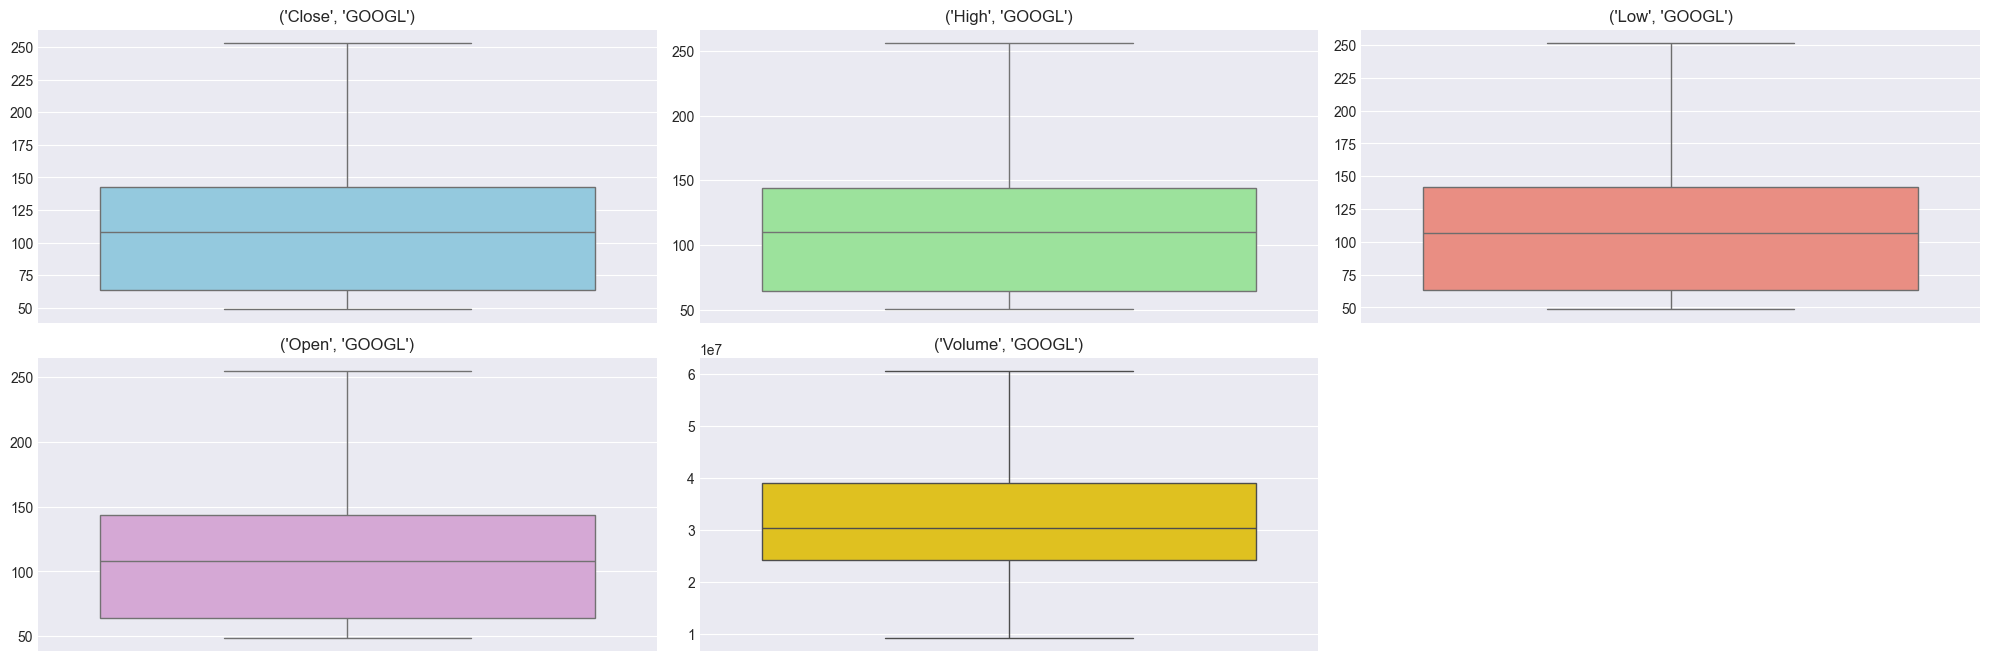

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(20, 10))  # 2 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise']

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=colors[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('')

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<h2 style="color: cyan; text-align: center">ANALYSE EXPLORATOIRE </h2>

In [14]:
# EFFECTUONS UNE STATISTIQUE DESCRIPTIVE
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL
count,2002.000000,2002.000000,2002.000000,2002.000000,2.002000e+03
mean,112.774417,113.997546,111.513347,112.729480,3.303173e+07
std,50.199340,50.728319,49.709023,50.228521,1.179404e+07
min,48.864296,50.226501,48.516422,48.846925,9.312000e+06
25%,64.071764,64.375227,63.185593,63.752306,2.432268e+07
50%,108.179131,110.087204,106.455900,107.921820,3.042950e+07
75%,142.913177,144.351828,141.724168,143.103133,3.897872e+07
max,253.134430,256.192412,251.645396,254.263681,6.051200e+07


* effectuons les visualisations: **Histogrammes**

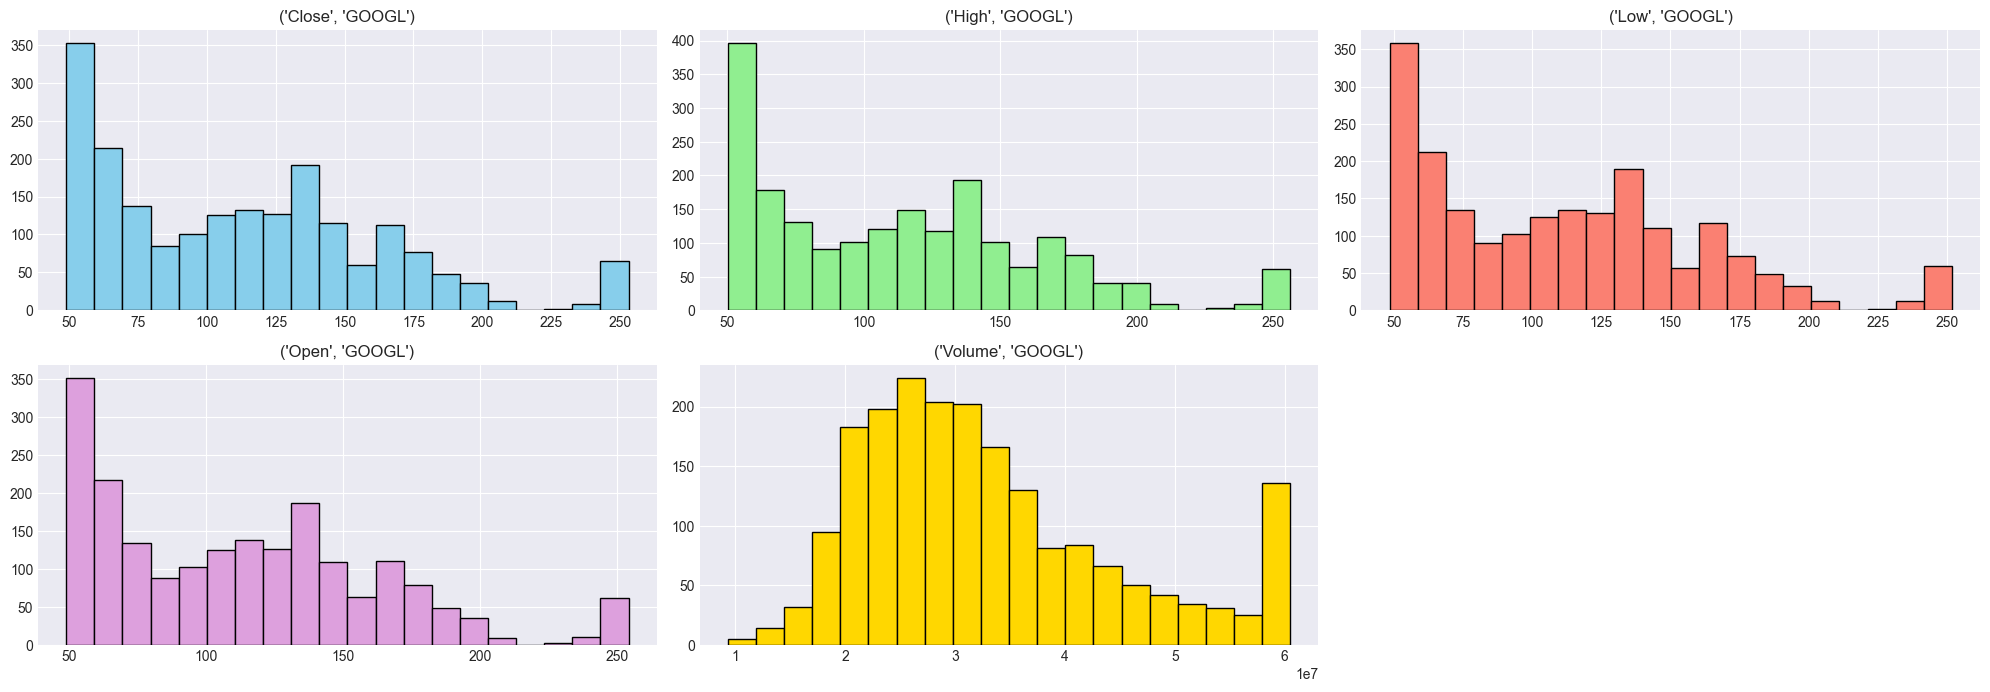

In [15]:

fig, axes = plt.subplots(3, 3, figsize=(20, 10))  # 3 lignes, 3 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise']

for i, col in enumerate(num_cols):
    axes[i].hist(df[col],bins=20,color=colors[i],edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

* effectuons une analyse bivariée: **Matrice de correlation**

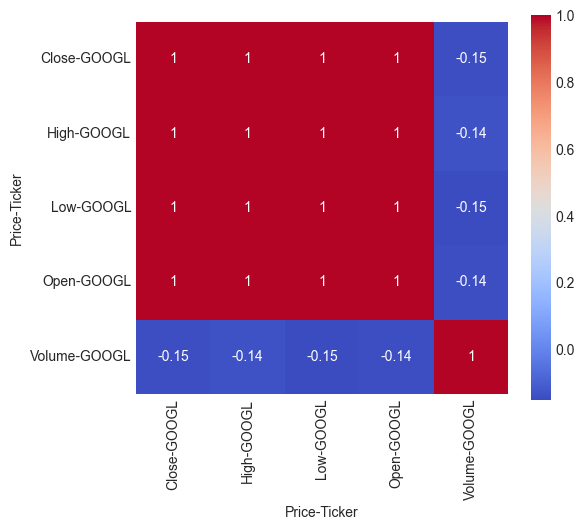

In [16]:
corr=df[num_cols].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr,annot=True,cmap='coolwarm',square=True)
plt.show()

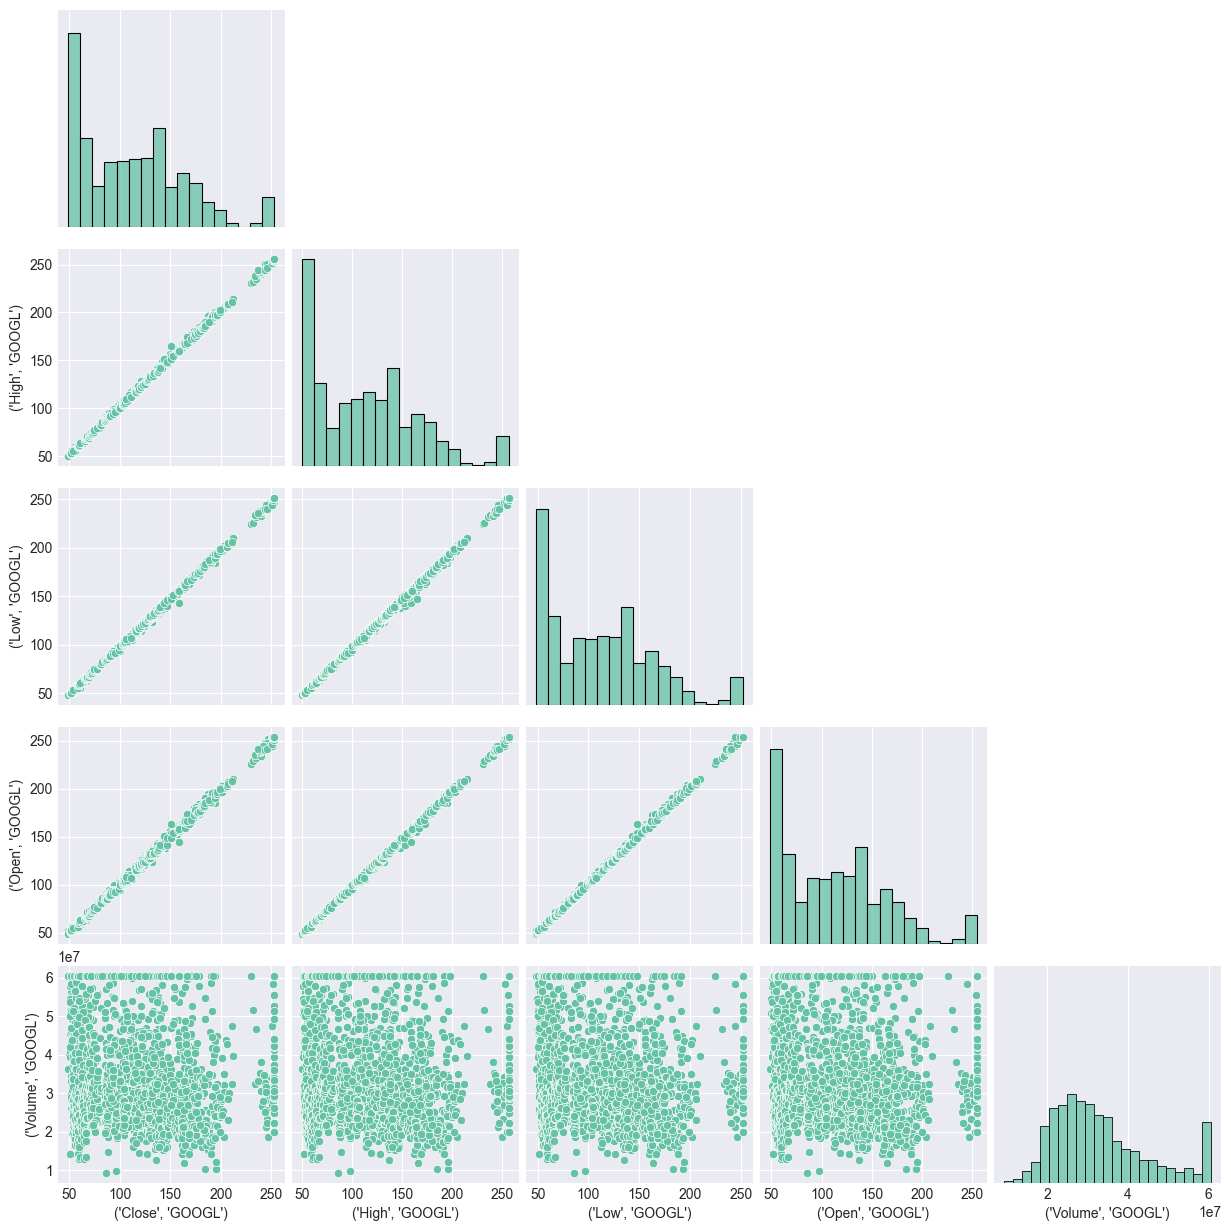

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# df = ton DataFrame
sns.pairplot(
    df,
    corner = True        # évite les doublons (plus propre)
)

plt.show()


##### interprétation
On peut constater que nos variables sont très correlées entre elles, sauf la variable **Volume-GOOGL**. On peut en déduire que, il n'est pas necessaire d'analyser toutes nos variables, On va se contenter de **Volume-GOOGL** et d'une variable parmis les 4 variables extrêmement correlées(car les résultats de l'un se réflète directement sur les trois autres). Ici, on choisit la première variable **Close_GOOGL**

<h2 style="color: cyan; text-align: center">VISUALISATION DES DONNÉES </h2>

Nous allons visualiser nos deux variables : **Volume-GOOGL** et **Close-GOOGL**

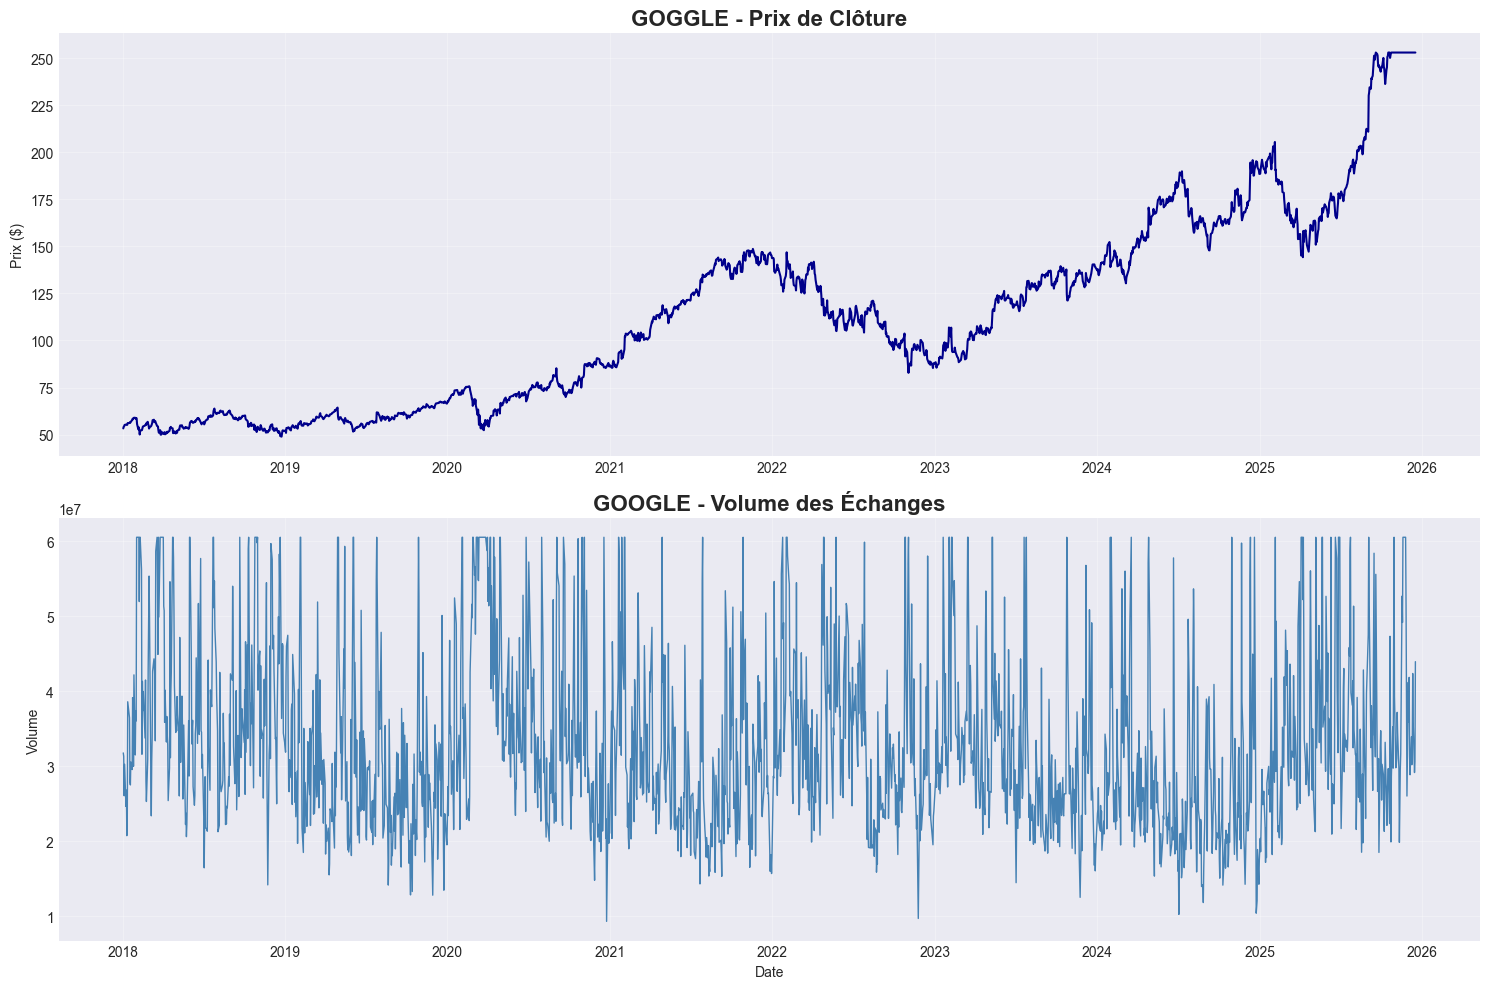

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))
data=df['Close']
# Prix de clôture
axes[0].plot(df.index, df['Close'], linewidth=1.5, color='darkblue')
axes[0].set_title('GOGGLE - Prix de Clôture', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Prix ($)')
axes[0].grid(True, alpha=0.3)

# Volume des échanges
axes[1].plot(df['Volume'], linewidth=1, color='steelblue')
axes[1].set_title('GOOGLE - Volume des Échanges', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##### INTERPRÉTATION

* On peut constater que le prix de clòture de notre action est relativement stable entre les années 2018 à 2020. Puis, elle subit une chutte drastique probablement due aux nombreuses crises(COVID-19 par exemple).</br>
Après cela, on constate une croissance de ce prix jusqu'en 2022, et puis une rechutte,lente, au fil des mois jusqu'en 2023, et à partir de là, on a une autre croissance, cette fois ci parsemée de petite rechutte brusques, notament en fin d'année 2024 , et en début 2025
</br>

* Pour le volume d'échange, on constate un variance très élevée entre 2018 jusqu'à nos jours. Le graphe n'étant pas très interprétable dans son état, nous allons faire les interprétations par bloc de deux années: 2018-2020, puis 2020-2022, 2022-2024 et enfin 2024-aujourd'hui

In [19]:
#choisir l'actif à analyser 
TICKER = 'GOOGL'
# Période de télégergement 
START_DATE1 = '2018-01-01'
END_DATE1 = '2020-01-01'
print(f"téléchargement des données {TICKER}...")
print(F" Période :{START_DATE1} à {END_DATE1}")

#téléchargement des données 
donnée_tronq1 = yf.download(TICKER, start = START_DATE1, end = END_DATE1, progress = False)
print(f"\n téléchargement reussi!")
print(f"{len(donnée_tronq1)} jours de donnees")
print(f"colonnes:{list(donnée_tronq1.columns)}")

# Période de télégergement 
START_DATE2 = '2020-01-01'
END_DATE2 = '2022-01-01'
print(f"téléchargement des données {TICKER}...")
print(F" Période :{START_DATE2} à {END_DATE2}")

#téléchargement des données 
donnée_tronq2 = yf.download(TICKER, start = START_DATE2, end = END_DATE2, progress = False)
print(f"\n téléchargement reussi!")
print(f"{len(donnée_tronq2)} jours de donnees")
print(f"colonnes:{list(donnée_tronq2.columns)}")


# Période de télégergement 
START_DATE3 = '2022-01-01'
END_DATE3 = '2024-01-01'
print(f"téléchargement des données {TICKER}...")
print(F" Période :{START_DATE3} à {END_DATE3}")

#téléchargement des données 
donnée_tronq3 = yf.download(TICKER, start = START_DATE3, end = END_DATE3, progress = False)
print(f"\n téléchargement reussi!")
print(f"{len(donnée_tronq3)} jours de donnees")
print(f"colonnes:{list(donnée_tronq3.columns)}")

# Période de télégergement 
START_DATE4 = '2024-01-01'
END_DATE4 = datetime.now().strftime('%Y-%m-%d')
print(f"téléchargement des données {TICKER}...")
print(F" Période :{START_DATE4} à {END_DATE4}")

#téléchargement des données 
donnée_tronq4 = yf.download(TICKER, start = START_DATE4, end = END_DATE4, progress = False)
print(f"\n téléchargement reussi!")
print(f"{len(donnée_tronq4)} jours de donnees")
print(f"colonnes:{list(donnée_tronq4.columns)}")




téléchargement des données GOOGL...
 Période :2018-01-01 à 2020-01-01

 téléchargement reussi!
503 jours de donnees
colonnes:[('Close', 'GOOGL'), ('High', 'GOOGL'), ('Low', 'GOOGL'), ('Open', 'GOOGL'), ('Volume', 'GOOGL')]
téléchargement des données GOOGL...
 Période :2020-01-01 à 2022-01-01

 téléchargement reussi!
505 jours de donnees
colonnes:[('Close', 'GOOGL'), ('High', 'GOOGL'), ('Low', 'GOOGL'), ('Open', 'GOOGL'), ('Volume', 'GOOGL')]
téléchargement des données GOOGL...
 Période :2022-01-01 à 2024-01-01

 téléchargement reussi!
501 jours de donnees
colonnes:[('Close', 'GOOGL'), ('High', 'GOOGL'), ('Low', 'GOOGL'), ('Open', 'GOOGL'), ('Volume', 'GOOGL')]
téléchargement des données GOOGL...
 Période :2024-01-01 à 2025-12-19

 téléchargement reussi!
494 jours de donnees
colonnes:[('Close', 'GOOGL'), ('High', 'GOOGL'), ('Low', 'GOOGL'), ('Open', 'GOOGL'), ('Volume', 'GOOGL')]


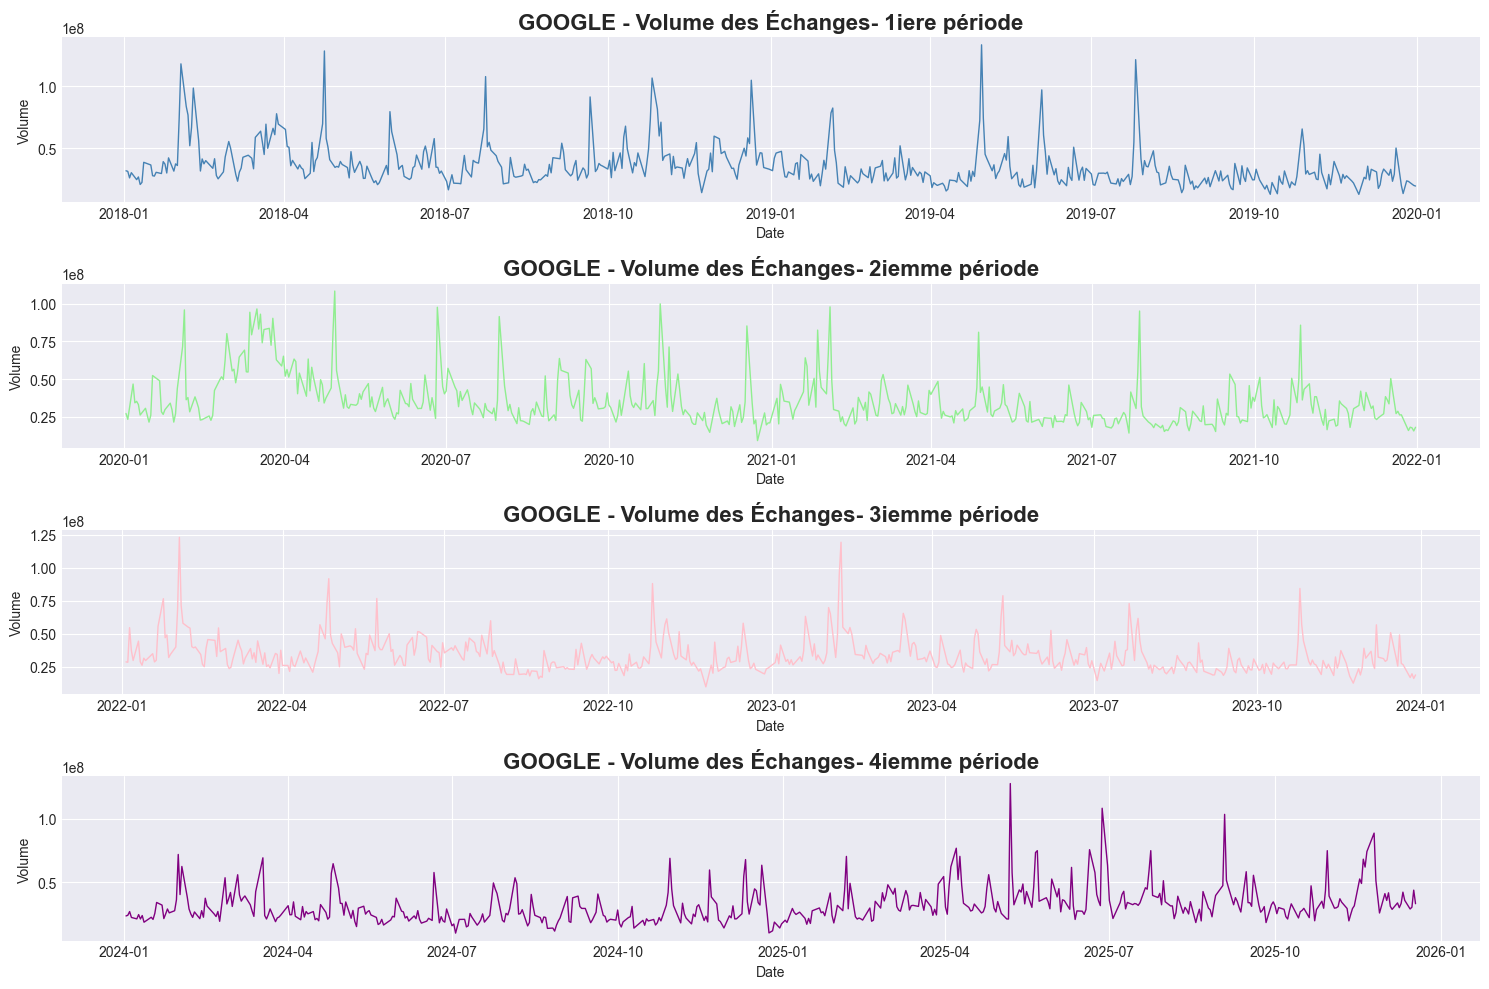

In [20]:
fig, axes = plt.subplots(4, 1, figsize=(15, 10))
# Volume des échanges
axes[0].plot(donnée_tronq1['Volume'], linewidth=1, color='steelblue')
axes[0].set_title('GOOGLE - Volume des Échanges- 1iere période', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Volume')
axes[0].set_xlabel('Date')
axes[0].grid(True)

axes[1].plot(donnée_tronq2['Volume'], linewidth=1, color='lightgreen')
axes[1].set_title('GOOGLE - Volume des Échanges- 2iemme période', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Date')
axes[1].grid(True)

axes[2].plot(donnée_tronq3['Volume'], linewidth=1, color='pink')
axes[2].set_title('GOOGLE - Volume des Échanges- 3iemme période', fontsize=16, fontweight='bold')
axes[2].set_ylabel('Volume')
axes[2].set_xlabel('Date')
axes[2].grid(True)

axes[3].plot(donnée_tronq4['Volume'], linewidth=1, color='purple')
axes[3].set_title('GOOGLE - Volume des Échanges- 4iemme période', fontsize=16, fontweight='bold')
axes[3].set_ylabel('Volume')
axes[3].set_xlabel('Date')
axes[3].grid(True)

plt.tight_layout()
plt.show()

##### INTERPRÉTATIONS
Les shémas sont bien plus lisibles maintenant, parfaits pour nos interprétations
* on constate que, les volumes atteingnent des pics très rapidement, mais chuttent aussi très rapidement. La variance est donc très élevée

* Comme autre remarque, on voit que , pour chaque bloc d'année, la volume échnagé est toujours très bas vers la fin de la période, et aussi ver le début d'une nouvelle année.cela eut être du au commencement de la nouvelle année et donc de nouveaux plan d'investissement par les investisseurs qui préparent la nouvelle année, ou bien d'autres raisons...

* Contrairement à ces périodes là, les mois de **février**, **mai**, **août**(sauf en août 2022: pleine période COVID) connaissent de très hauts  pics tous les ans

<h2 style="color: cyan; text-align: center">TEST DE STATIONNARITÉ </h2>

Pour pouvoir construire notre modèle, nous devons vérifier que nos données sont stationnaires car la stationnarité
améliore fortement l'apprentissage

Pour cela, nous allons éffectuer le test **ADF** (*Augmented Dickey-Fuller*) : H0 = série NON stationnaire

In [21]:
def test_stationarite(series, name='Série'):
    # Test ADF
    print(f"\n{'='*60}")
    print(f"TEST DE STATIONNARITÉ ADF (Augmented Dickey-Fuller): {name}")
    print(f"{'='*60}\n")
    
    adf_result = adfuller(series.dropna())
    print(f"   P-value : {adf_result[1]:.6f}")
    
    if adf_result[1] < 0.05:
        print(f" STATIONNAIRE (p < 0.05)")
    else:
        print(f" NON STATIONNAIRE (p >= 0.05)")
    return f"{adf_result[1]:.6f}"

# Test sur les prix de clôture
adf_price = test_stationarite(df['Close'], 'Prix de Clôture GOOGL')
# Test sur le volume
adf_price = test_stationarite(df['Volume'], 'Volume des échanges GOOGL')


TEST DE STATIONNARITÉ ADF (Augmented Dickey-Fuller): Prix de Clôture GOOGL

   P-value : 0.992530
 NON STATIONNAIRE (p >= 0.05)

TEST DE STATIONNARITÉ ADF (Augmented Dickey-Fuller): Volume des échanges GOOGL

   P-value : 0.000000
 STATIONNAIRE (p < 0.05)


##### INTERPRÉTATION


* Pour la variable Volume_GOOGL, on a un cas de stationarité(car p_value<0.05): ceci est bon pour les modèles LSTM
* Pour la variable Close_GOOGL, on a un cas de non-stationarité(car p_value>0.05): Ceci est un problème pour la suite. Nous devons faire une **différenciation** nos données

In [22]:
données_différentiées=df['Close'].diff()


In [23]:
#Vérification
adf_price = test_stationarite(données_différentiées, 'Prix de Clôture GOOGL')


TEST DE STATIONNARITÉ ADF (Augmented Dickey-Fuller): Prix de Clôture GOOGL

   P-value : 0.000000
 STATIONNAIRE (p < 0.05)


Nos données sont maintenant stationnaires. Nous pouvons continuer avec notre modèle

<h2 style="color: cyan; text-align: center">NORMALISATION DES DONNÉES</h2>

Après la présélection précédente, nous sommes restés avec deux cariables: Le *Volume* et le *Prix de clôture*.

Pour la suite, on trouve qu'il serais plus pertinant d'étudier le *Prix de clôture* plutôt que du volume car c'est un paramètre très capital pour les investisseurs dans les marchés financiers.

Faisons donc une brève descriptions de notre variable sélectionnée:

In [24]:
df['Close'].describe()

Ticker,GOOGL
count,2002.000000
mean,112.774417
std,50.199340
min,48.864296
25%,64.071764
50%,108.179131
75%,142.913177
max,253.134430


Maintenant, passons à la *Normalisation des données* proprement dite: C'est une étape trÈs importante car nos modèles sont très sensibles aux échelles des données. Elle consiste à ramener les valeurs des colonnes numériques d'un ensemble de données à une **échelle commune**([0,1]), sans déformer les différences dans les plages de valeurs.

In [25]:
data=df['Close']
scaler = MinMaxScaler(feature_range=(0, 1))
data_norm = scaler.fit_transform(data)

print(f" Normalisation effectuée")
print(f"   Valeur minimale normalisée : {data_norm.min():.4f}")
print(f"   Valeur maximale normalisée : {data_norm.max():.4f}")
print(f"   Moyenne normalisée : {data_norm.mean():.4f}") 

 Normalisation effectuée
   Valeur minimale normalisée : 0.0000
   Valeur maximale normalisée : 1.0000
   Moyenne normalisée : 0.3129


Notre feature 'Close' (data_norm) est prêt pour le modèle


<div style="background-color:red"><h4 style="color:black;text-align:center">Notre base de données est désormais prête à être à être utilisée pour nos modèles: RNN ET LSTM </h4></div>

<div style="background-color:lightblue"><h1 style="color:black;text-align:center">UTILISATION DES MODÈLES DE RNN: RNN CLASSIQUE ET RNN AVEC MÉCANISME D'ATTENTION</h1></div>


<h2 style="color: cyan; text-align: center">PRÉDICTION DES TENDANCES BOIURSIÈRES AVEC UN LSTM CLASSIQUE</h2>

Un **RNN**(*Recurrent Neural Network*) est un réseau de neurones concu pour traiter des données séquentielles(texte,series temporelles,...). Il utilise une memoire interne appele etat cache qui se propage d'un pas de temps au suivant.

<h3 style="color: lightgreen; text-align: center">CRÉATION DES SÉQUENCES (fenêtres temporelles) </h3>

c'est une étape indispensable car un RNN n'apprend pas sur une seule valeur, mais sur une suite de valeurs passées. Nous transformons donc nos données d'entrée sous forme de séquences

In [26]:
def create_sequences(data_norm, time_steps=10):
    X, y = [], []
    for i in range(len(data_norm)- time_steps):
        X.append(data_norm[i:i+time_steps])
        y.append(data_norm[i+time_steps])
    return np.array(X), np.array(y)
X, y = create_sequences(data_norm, time_steps=10)

<h3 style="color: lightgreen; text-align: center">SEPARATION EN DONNEES TRAIN/TEST </h3>

In [27]:
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"forme des données{X_train.shape}")

forme des données(1593, 10, 1)


<h3 style="color: lightgreen; text-align: center">CONSTRUCTION D'UN MODELE RNN CLASSIQUE (1 COUCHE) </h3>

Nous allons d'abord commence par construire un modele de RNN basique

In [28]:
model_1 = Sequential()
model_1.add(SimpleRNN(
units=50,
activation='relu',
input_shape=(X_train.shape[1], X_train.shape[2])
))
model_1.add(Dense(1))
print("ARCHITECTURE DU MODÈLE\n")
model_1.summary()

ARCHITECTURE DU MODÈLE



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Early Stopping : Arrête l'entraînement si la performance ne s'améliore plus
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Attend 5 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)
# Reduce Learning Rate : Réduit le taux d'apprentissage quand la métrique stagne
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Réduit le LR de moitié
    patience=3,
    min_lr=0.00001,
    verbose=1
)

model_1.compile(
optimizer='adam',
loss='mse',
metrics=['mae']
)

##### ENTRAINEMENT
Entraînons notre modèle

In [30]:
history_1 = model_1.fit(
X_train,
y_train,
epochs=50,
batch_size=32,
validation_data=(X_test, y_test),
callbacks=[early_stopping, reduce_lr],
verbose=1
)

Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - loss: 0.0028 - mae: 0.0315 - val_loss: 0.0011 - val_mae: 0.0278 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.4388e-04 - mae: 0.0088 - val_loss: 4.6191e-04 - val_mae: 0.0159 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.3008e-04 - mae: 0.0081 - val_loss: 4.2607e-04 - val_mae: 0.0153 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.2730e-04 - mae: 0.0080 - val_loss: 4.1030e-04 - val_mae: 0.0145 - learning_rate: 0.0010
Epoch 5/50
48/50 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.2481e-04 - mae: 0.0078
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.2415e-04 - mae: 0.0079 - val_loss: 4.6981e-04 - val_mae: 0.0170 - learning_rate: 0.0010
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.2351e-04 - mae: 0.0078 - val_loss: 3.8823e-04 - val_m

On a eu un early stopping. Le modèle s'arrête à environ 18 époch

##### Visualisation des courbes d'erreur

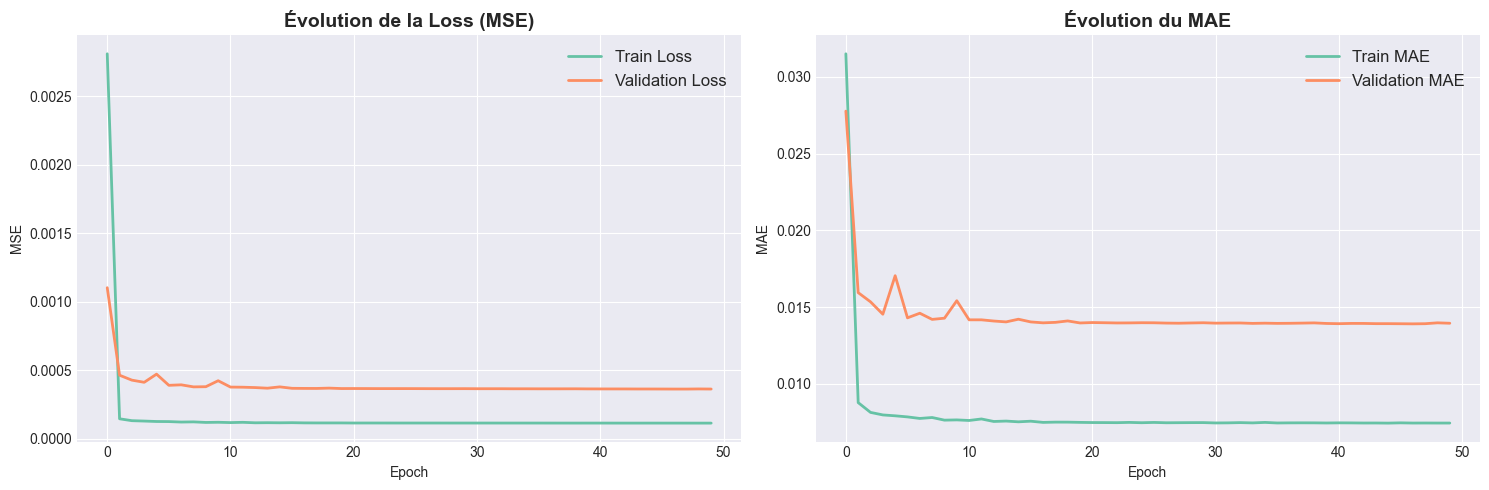

In [31]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history_1.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_1.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history_1.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history_1.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

##### INTERPRÉTATIONS
* Les deux modèles ont une tentence plutôt constante. On n'a pas d'overfitting
* Nous devons déterminer les métrique pour bien capter la performance du modèle

<h4 style="color: lightblue; text-align: center"> Prédictions et évaluation du modèle</h4>

In [32]:
y_pred_1 = model_1.predict(X_test)
#Retour à l’échelle originale
y_test_inv_1 = scaler.inverse_transform(y_test)
y_pred_inv_1 = scaler.inverse_transform(y_pred_1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


##### Visualisation

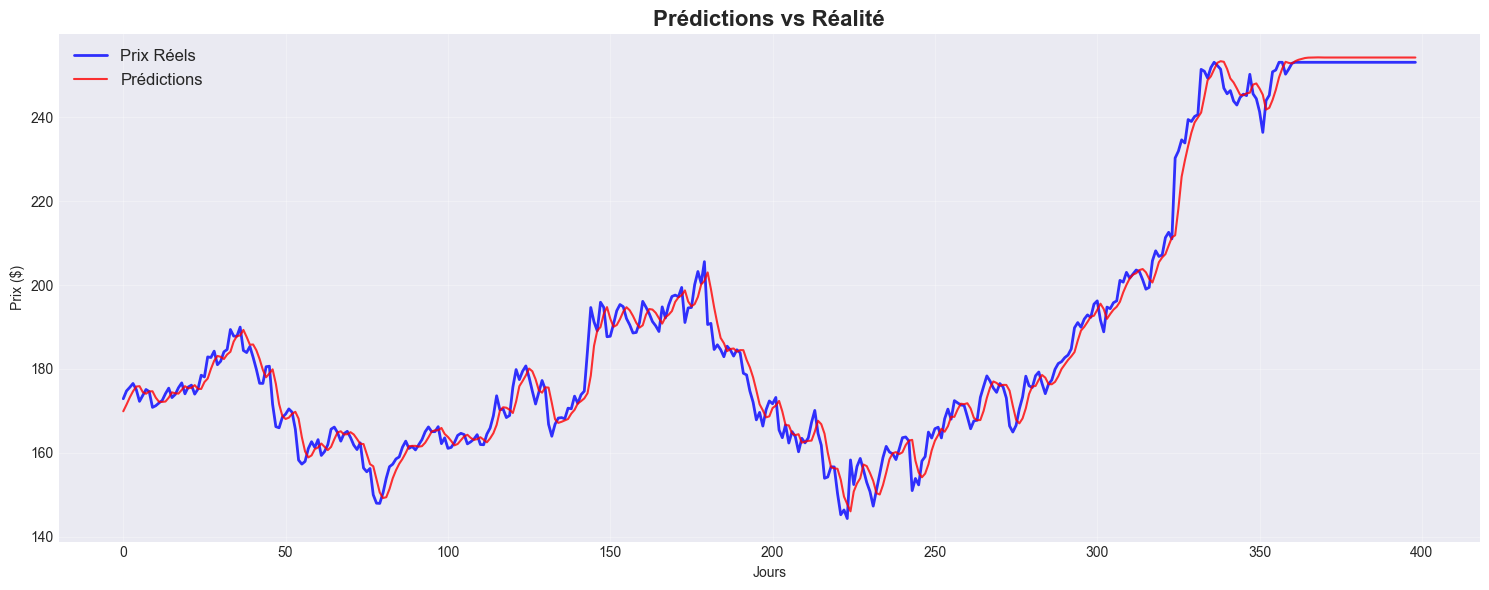

In [33]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_1, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_1, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### Évaluation des métrique

In [34]:
mse_1=np.mean((y_test_inv_1-y_pred_inv_1)**2)
print(f"MSE: {mse_1:.4f}")
rmse_1=np.sqrt(mse_1)
print(f"RMSE: {rmse_1:.4f}")
mae_1 = mean_absolute_error(y_test_inv_1, y_pred_inv_1)
print(f"MAE : {mae_1:.4f}")

MSE: 15.0602
RMSE: 3.8807
MAE : 2.8437


Les métriques sont assez bonnes: 

* Une MAE de $\approx 4.1185$  signifie qu'en moyenne, les prédictions
   du modèle s'écartent d'environ $4.1185\$ $ des valeurs réelles: Cela montre une assez bonne performance de motre modèle.
* On voit que la courbe en rouge (prédictions) essaie de capturer au mieux la tendance des données réelles. Néanmoins, on peut constater quelques zones où les écarts entre les deux courbes sont assez grands

<h3 style="color: lightgreen; text-align: center"> CONSTRUCTION D'UN MODÈLE DE RNN PROFOND (plusieurs couches) </h3>

In [35]:
model_2 = Sequential()
model_2.add(SimpleRNN(50, return_sequences=True, input_shape=(X_train.shape[1],
X_train.shape[2])))
model_2.add(Dropout(0.2))
model_2.add(SimpleRNN(50))
model_2.add(Dropout(0.2))
model_2.add(Dense(1))
model_2.compile(optimizer='adam', loss='mse')
print("ARCHITECTURE DU MODÈLE\n")
model_2.summary()

ARCHITECTURE DU MODÈLE



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 10, 50)         │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,701 (30.08 KB)

 Trainable params: 7,701 (30.08 KB)

 Non-trainable params: 0 (0.00 B)

#### ENTRAÌNEMENT DU MODÈLE

Comme dans le cas précédent, nous allons utiliser "***adam***" comme modèle d'optimisation, connu pour son adaptabilité, sa grande stabilité, et sa rapitdité de convergence.

Et aussi la fonction de perte "***MSE***",très adapté pour les tâches de regression

In [36]:
# Compilation du modèle
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=1.0),#Empêche l’explosion du gradient
    loss="mse",
    metrics=['mae']
)

In [37]:
# Early Stopping : Arrête l'entraînement si la performance ne s'améliore plus
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Attend 5 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)

# Reduce Learning Rate : Réduit le taux d'apprentissage quand la métrique stagne
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Réduit le LR de moitié
    patience=3,
    min_lr=0.00001,
    verbose=1
)

# Model Checkpoint : Sauvegarde le meilleur modèle


# Entraîner le modèle
history_2 = model_2.fit(
    X_train, 
    y_train,
    epochs=100,
    batch_size=25,
    validation_data=(X_test,y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)



Epoch 1/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.0446 - mae: 0.1365 - val_loss: 0.0429 - val_mae: 0.1804 - learning_rate: 5.0000e-04
Epoch 2/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0114 - mae: 0.0749 - val_loss: 0.0127 - val_mae: 0.0834 - learning_rate: 5.0000e-04
Epoch 3/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0073 - mae: 0.0601 - val_loss: 0.0111 - val_mae: 0.0756 - learning_rate: 5.0000e-04
Epoch 4/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0053 - mae: 0.0505 - val_loss: 0.0084 - val_mae: 0.0654 - learning_rate: 5.0000e-04
Epoch 5/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0042 - mae: 0.0457 - val_loss: 0.0103 - val_mae: 0.0779 - learning_rate: 5.0000e-04
Epoch 6/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0036 - mae: 0.0423 - val_loss: 0.0114 - val_mae: 0.0850 - learning_rate: 5.0000e-04
Epoch 7/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0031 - mae: 0.0393 - val_loss: 0.0062 - val_mae: 0.0584 - lear

#### Visualisation des courbes des erreurs

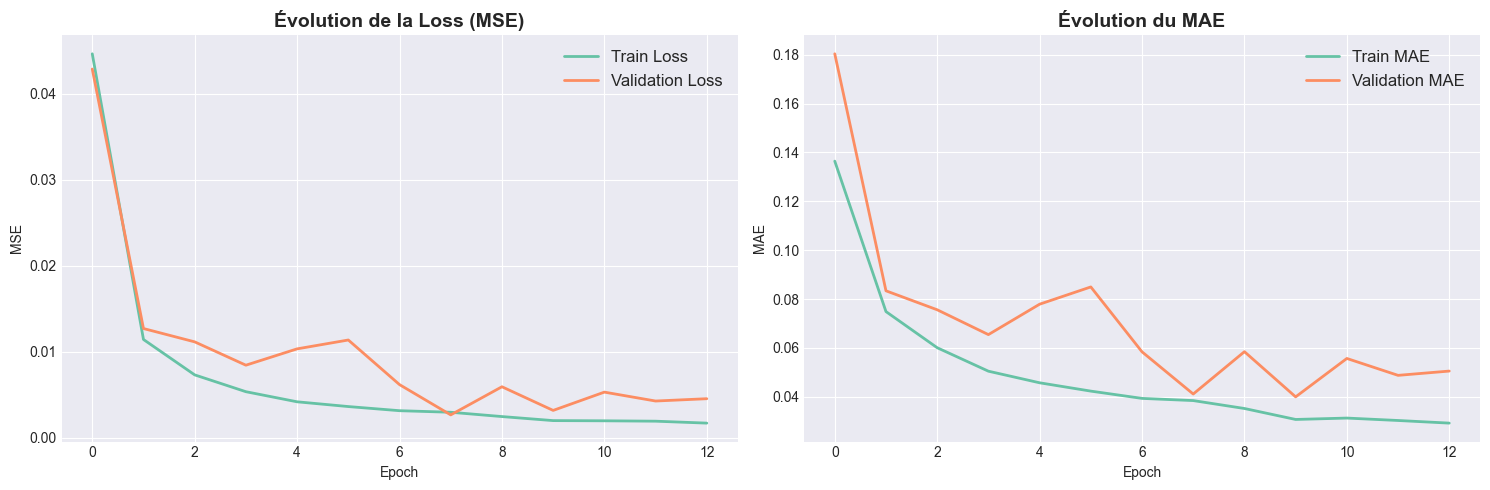

In [38]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history_2.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_2.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history_2.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history_2.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

##### INTERPRÉTATION

* Les deux courbes d'entraînement sont décroissantes. 
* Les courbes de validation ont aussi une tendance générale decroissante, ce qui montre qu'on a pas de surapprentissage. 
* Environ à l'époque 8, on a une valeur minimale des deux coté pour la validation. à cet environ, le modèle est optimal

##### Prédiction

In [39]:
y_pred_2 = model_2.predict(X_test)
#Retour à l’échelle originale
y_test_inv_2 = scaler.inverse_transform(y_test)
y_pred_inv_2 = scaler.inverse_transform(y_pred_2)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step


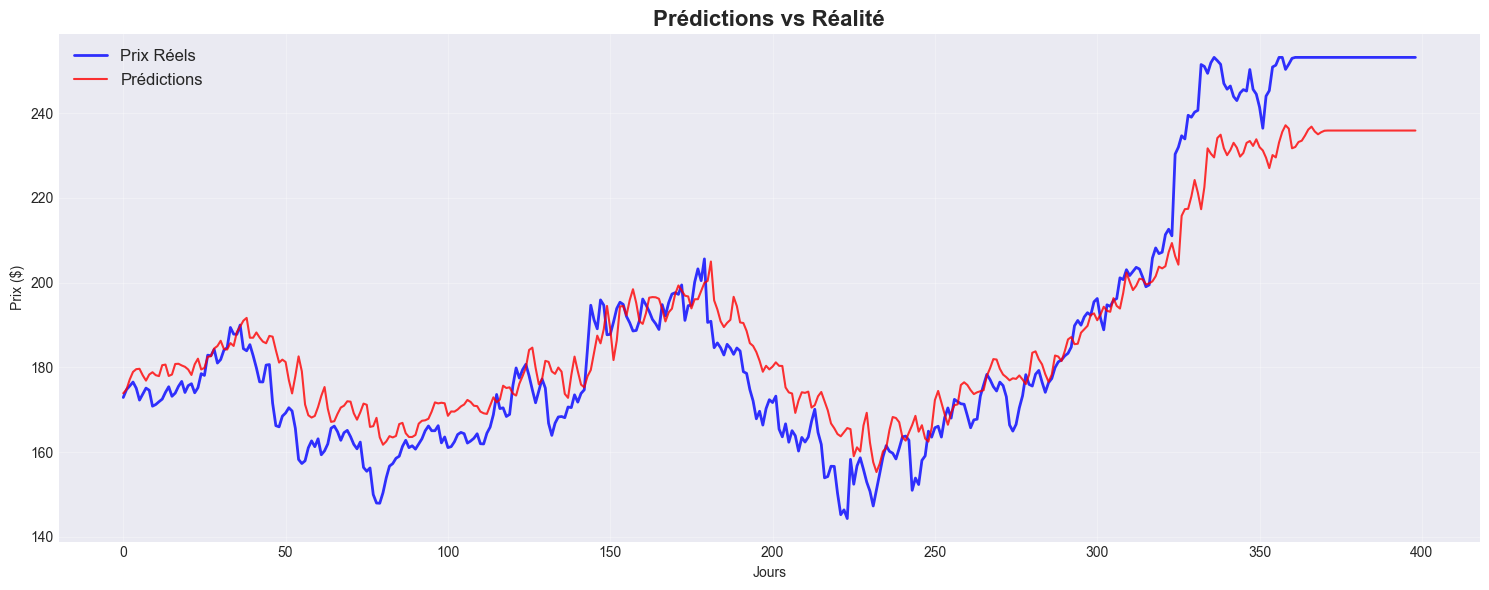

In [40]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_2, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_2, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### Prédiction 

In [41]:
mse_2=np.mean((y_test_inv_2-y_pred_inv_2)**2)
print(f"MSE: {mse_2:.4f}")
rmse_2=np.sqrt(mse_2)
print(f"RMSE: {rmse_2:.4f}")
mae_2 = mean_absolute_error(y_test_inv_2, y_pred_inv_2)
print(f"MAE : {mae_2:.4f}")

MSE: 110.5199
RMSE: 10.5128
MAE : 8.3985


##### Interprétation

* les métriques sont certe faible mais sont moins bonnes que les métriques précédentes
* Ceci signifie que, notre modèle est déjà assez bon avec une seule couche. ajouter des couches supplémentaires est juste superflu. D'où la baisse des performances

Regardons maintenant notre modèle lorsque nous faisons une validation croisée

<h3 style="color: lightgreen; text-align: center"> VALIDATION CROISEE TEMPORELLE </h3>

La validation croisee respecte l'ordre chrolnologique  des donnees temporelles en ceci que :
* L'ordre doit être preserve

* Eviter de mélanger les donnees passees et futures

* Les donnees futures ne doivent pas fuiter l'entrainement.

Pour un RNN,cette validation est cruciale car :
* ils capturent les patterns essentiels

* Empeche l'utilisation d'information future

* simule la prediction en temps reel

In [42]:
tscv = TimeSeriesSplit(n_splits=5)
for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

model_3 = Sequential()
model_3.add(SimpleRNN(50, input_shape=(X_train.shape[1],
X_train.shape[2])))
model_3.add(Dense(1))
model_3.compile(optimizer='adam', loss='mse', metrics=["mae"])
model_3.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)
print('[MSE, MAE]:', model_3.evaluate(X_test, y_test, verbose=0))

[MSE, MAE]: [0.000521872949320823, 0.017944088205695152]


Ces deux métriques sont très bonnes car elles sont très proches de 0

<h4 style="color: lightblue; text-align: center"> Prédiction et retour à l'échelle </h4>

In [43]:
y_pred_3 = model_3.predict(X_test)
y_test_inv_3 = scaler.inverse_transform(y_test)
y_pred_inv_3 = scaler.inverse_transform(y_pred_3)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


<h4 style="color: lightblue; text-align: center"> Visualisation et prédiction </h4>

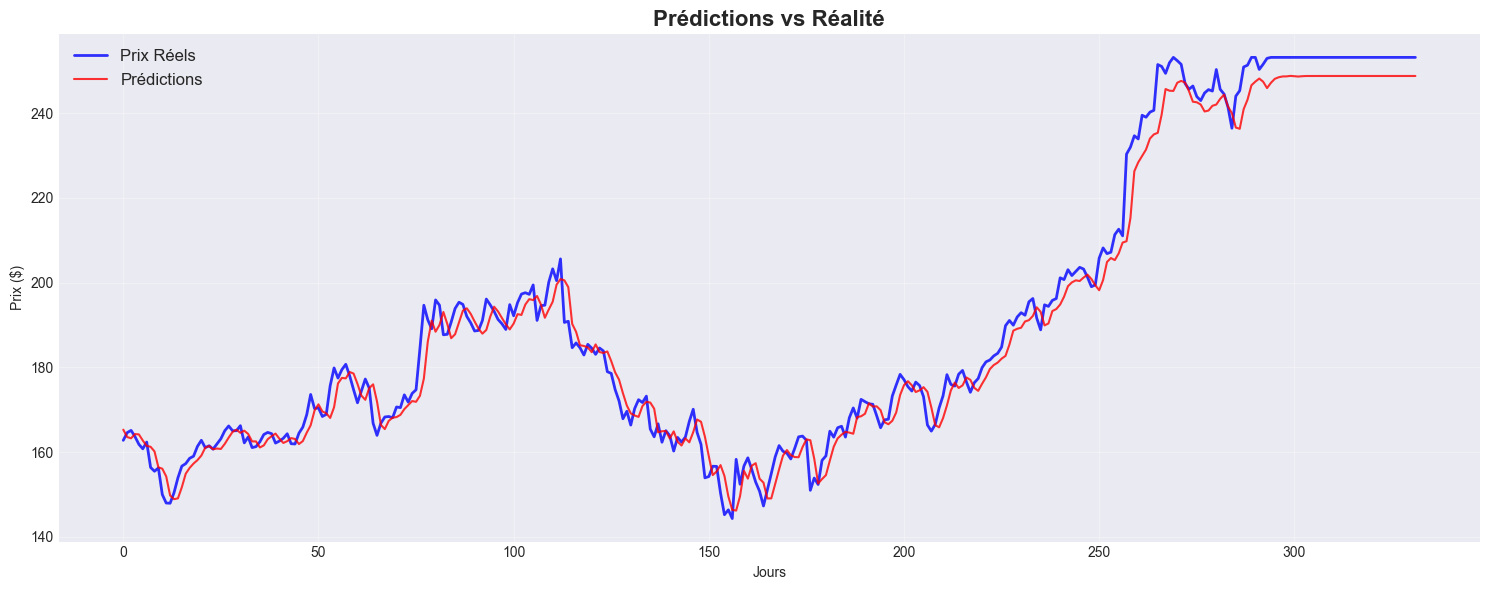

In [44]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_3, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_3, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
mse_3=np.mean((y_test_inv_3-y_pred_inv_3)**2)
print(f"MSE: {mse_3:.4f}")
rmse_3=np.sqrt(mse_3)
print(f"RMSE: {rmse_3:.4f}")
mae_3 = mean_absolute_error(y_test_inv_3, y_pred_inv_3)
print(f"MAE : {mae_3:.4f}")

MSE: 21.7758
RMSE: 4.6665
MAE : 3.6654


#### Interprétation

On constate que ce modèle a apporter une nette ammélioration par rapport au modèle précédent.

La validation croisée, encore une fois , est prouvé être un très bon moyen d'amélioration des modèles

<h3 style="color: lightgreen; text-align: center">RNN CLASSIQUE AVEC MÉCANISME D'ATTENTION SIMPLE (avec une couche)</h3>

<h4 style="color: lightblue; text-align: center">CONSTRUCTION DU MODÈLE</h3>

In [46]:
class Attention(Layer):
    def __init__(self):
        super().__init__()

    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
initializer='random_normal', trainable=True)
        self.b = self.add_weight(shape=(input_shape[1], 1),
initializer='zeros', trainable=True)
        
    def call(self, inputs):
        # inputs : (batch_size, time_steps, hidden_units)
        e = tf.keras.backend.tanh(tf.keras.backend.dot(inputs, self.W) +
self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        return tf.keras.backend.sum(inputs * a, axis=1)

In [47]:
model_4 = Sequential()
model_4.add(SimpleRNN(
    units=50,
    activation='relu',
    return_sequences=True,
    input_shape=(X_train.shape[1], X_train.shape[2])
))
model_4.add(Attention())
model_4.add(Dense(1))

model_4.compile(optimizer='adam', loss='mse')
model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 10, 50)         │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (Attention)           │ (None, 50)             │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,711 (10.59 KB)

 Trainable params: 2,711 (10.59 KB)

 Non-trainable params: 0 (0.00 B)

##### Entraînement du modèle

In [48]:
# Compilation du modèle
model_4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=1.0),#Empêche l’explosion du gradient
    loss="mse",
    metrics=['mae']
)

# Early Stopping : Arrête l'entraînement si la performance ne s'améliore plus
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Attend 5 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)

# Reduce Learning Rate : Réduit le taux d'apprentissage quand la métrique stagne
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Réduit le LR de moitié
    patience=3,
    min_lr=0.00001,
    verbose=1
)

# Model Checkpoint : Sauvegarde le meilleur modèle


# Entraîner le modèle
history_4 = model_4.fit(
    X_train, 
    y_train,
    epochs=100,
    batch_size=25,
    validation_data=(X_test,y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)



Epoch 1/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0126 - mae: 0.0709 - val_loss: 0.0062 - val_mae: 0.0678 - learning_rate: 5.0000e-04
Epoch 2/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 6.3173e-04 - mae: 0.0206 - val_loss: 0.0013 - val_mae: 0.0267 - learning_rate: 5.0000e-04
Epoch 3/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.6914e-04 - mae: 0.0143 - val_loss: 0.0014 - val_mae: 0.0283 - learning_rate: 5.0000e-04
Epoch 4/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 3.5226e-04 - mae: 0.0139 - val_loss: 0.0012 - val_mae: 0.0260 - learning_rate: 5.0000e-04
Epoch 5/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 3.5602e-04 - mae: 0.0140 - val_loss: 0.0012 - val_mae: 0.0257 - learning_rate: 5.0000e-04
Epoch 6/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 3.4936e-04 - mae: 0.0139 - val_loss: 0.0012 - val_mae: 0.0270 - learning_rate: 5.0000e-04
Epoch 7/100
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.4523e-04 - mae: 0.0137 - val_loss: 0.0012 -

#### VISUALISATION DES COURBES D'ERREUR

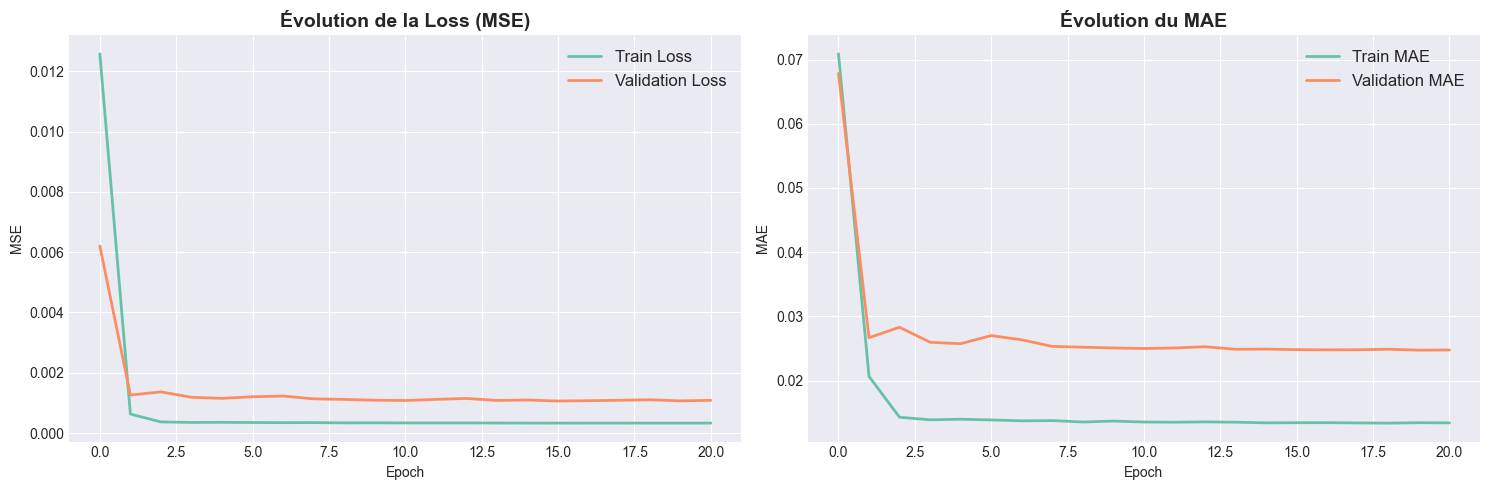

In [49]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history_4.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_4.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history_4.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history_4.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### INTERPRÉTATION

* On constate que, des deux cotés, les deux courbes, validation et entraînement, décroient ensemble. On a pas de surapprentissage
* Les métriques sont assez basses

#### PRÉDICTION

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


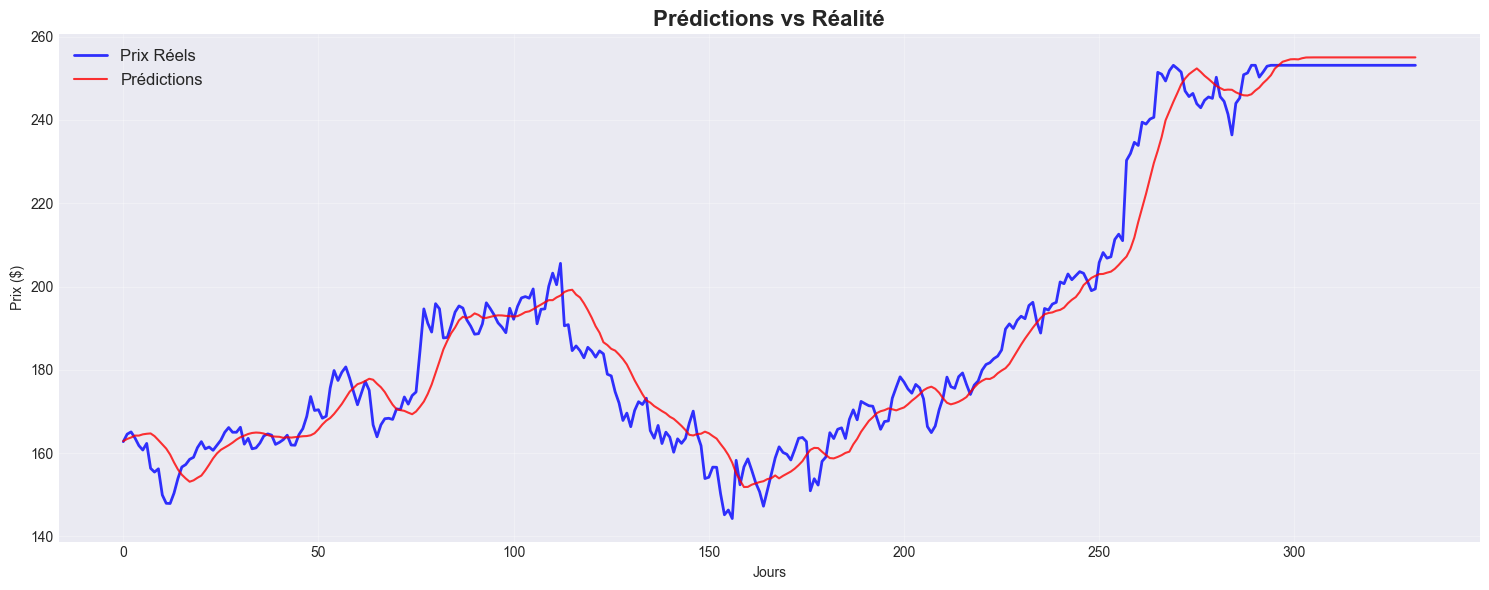

In [50]:
y_pred_4 = model_4.predict(X_test)
#Retour à l’échelle originale
y_test_inv_4 = scaler.inverse_transform(y_test)
y_pred_inv_4 = scaler.inverse_transform(y_pred_4)

# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_4, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_4, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### ÉVALUATION

In [51]:
mse_4=np.mean((y_test_inv_4-y_pred_inv_4)**2)
print(f"MSE: {mse_4:.4f}")
rmse_4=np.sqrt(mse_4)
print(f"RMSE: {rmse_4:.4f}")
mae_4 = mean_absolute_error(y_test_inv_4, y_pred_inv_4)
print(f"MAE : {mae_4:.4f}")

MSE: 44.2995
RMSE: 6.6558
MAE : 5.0676


#### INTERPRÉTATION

* Les métriques sont assez bas. Notre modèle est plutôt bon
* Néamoins le modèle sans mécanisme d'attention est plus performant que celui ci

<h3 style="color: lightgreen; text-align: center">RNN CLASSIQUE AVEC MÉCANISME D'ATTENTION PROFOND</h3>

<h4 style="color: lightblue; text-align: center">CONSTRUCTION DU MODÈLE avec validation croisée</h3>

In [52]:
tscv = TimeSeriesSplit(n_splits=5)
for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model_5 = Sequential()
    model_5.add(SimpleRNN(50, return_sequences=True,
input_shape=(X_train.shape[1], X_train.shape[2])))
    model_5.add(Attention())
    model_5.add(Dense(1))
    model_5.compile(optimizer='adam', loss='mse')
    model_5.fit(X_train, y_train, epochs=30, batch_size=32, verbose=0, callbacks=[early_stopping, reduce_lr])
    print('MSE:', model_5.evaluate(X_test, y_test, verbose=0))


MSE: 9.686501289252192e-05
MSE: 0.000544379698112607
MSE: 0.0007822338375262916
MSE: 0.0003734829369932413
MSE: 0.001490113907493651


##### INTERPRÉTATION

On constate que la MSE est très faible pour ce modèle. Il est donc très performant

##### Prédictions et retour a l'echelle

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


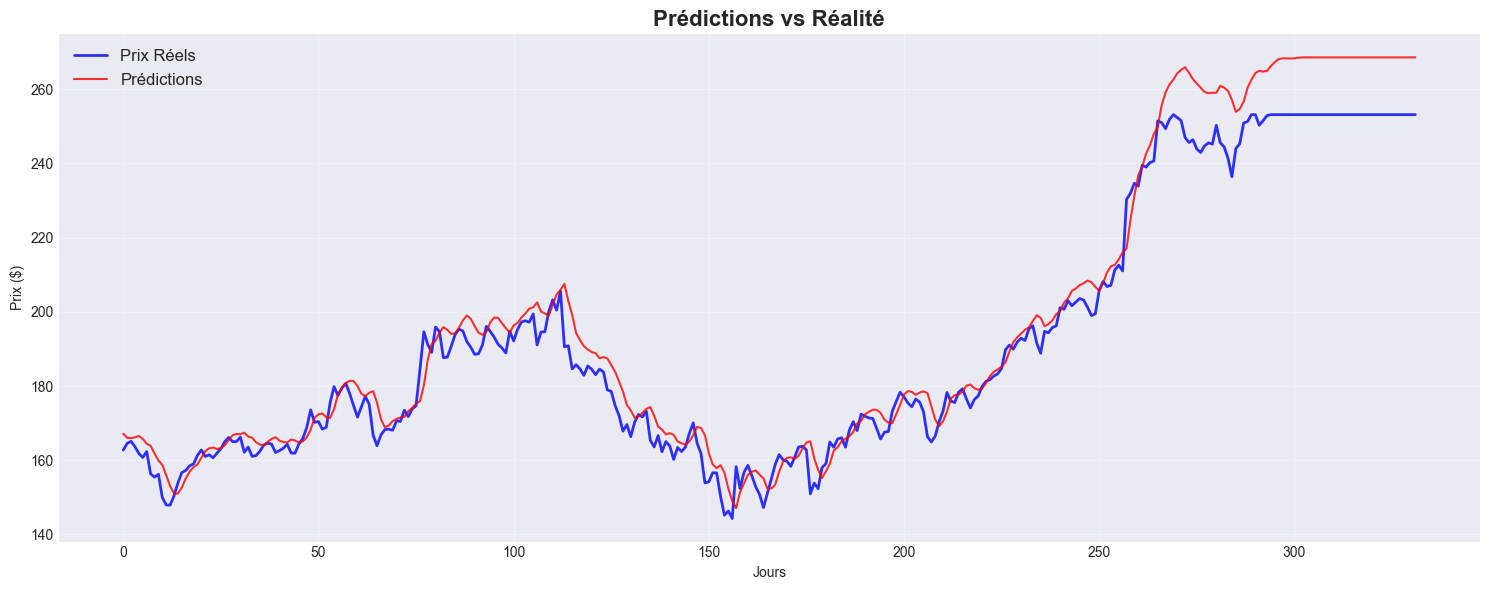

In [53]:
y_pred_5 = model_5.predict(X_test)

y_test_inv_5 = scaler.inverse_transform(y_test)
y_pred_inv_5 = scaler.inverse_transform(y_pred_5)

# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_5, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_5, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### ÉVALUATION

In [54]:
mse_5=np.mean((y_test_inv_5-y_pred_inv_5)**2)
print(f"MSE: {mse_5:.4f}")
rmse_5=np.sqrt(mse_5)
print(f"RMSE: {rmse_5:.4f}")
mae_5 = mean_absolute_error(y_test_inv_5, y_pred_inv_5)
print(f"MAE : {mae_5:.4f}")

MSE: 62.1769
RMSE: 7.8852
MAE : 5.8771


Comme prévu, on a de très bonnes performances pour ce modèle

<h2 style="color: cyan; text-align: center">SYNTHÈSE GÉNÉRALE DES MODÈLES RNN : CLASSIQUE ET MÉCANISME D'ATTENTION</h2>

De tout les modèles , le modèle RNN qui a présenté de meilleur performances est le modèle RNN Classique avec une seule couche. Il a présenté de meilleures performances. 

Ceci nous ammène à dire que, Dans certains cas, les modèles trop profonds ne sont pas toujours les plus performants. Il suffit souvant d'une seule couche pour ressortir les meilleurs prédictions

<div style="background-color:lightblue"><h1 style="color:black;text-align:center">UTILISATION DES MODÈLES DE LSTM: LSTM CLASSIQUE ET LSTM AVEC MÉCANISME D'ATTENTION</h1></div>


<h2 style="color: cyan; text-align: center">PRÉDICTION DES TENDANCES BOIURSIÈRES AVEC UN LSTM CLASSIQUE</h2>

Un **LSTM**(*Long Short-Term Memory*) est un réseau de neurones spécialisé pour les données séquentielles, et excellent dans la détection de ces tendances, offrant une compréhension plus fine et des prévisions plus précises des mouvements boursiers futurs. C'est donc un modèle très pertinant à étudier dans notre cas 

<h3 style="color: lightgreen; text-align: center">CRÉATION DES SÉQUENCES (fenêtres temporelles) </h3>

c'est une étape indispensable car un LSTM n’'apprend pas sur une seule valeur, mais sur une suite de valeurs passées. Nous transformons donc nos données d'entrée sous forme de séquences

In [55]:
def create_sequences(data, time_steps=10):
    X, y = [], []
    for i in range(len(data)- time_steps):
        X.append(data[i:i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

time_steps = 60#longueur d'une sequence
X, y = create_sequences(data_norm, time_steps)

#### Forme des données

In [56]:
print(f"   X shape : {X.shape} (échantillons, time_steps , feature)")
print(f"   y shape : {y.shape}")

   X shape : (1942, 60, 1) (échantillons, time_steps , feature)
   y shape : (1942, 1)


On a donc 1948 observations; chaque échantillon a 50 observations, et on a une seule feature

<h3 style="color: lightgreen; text-align: center">SÉPARATION EN DONNÉES D'ENTRAINEMENT ET DE TEST </h3>

Nous allons prendre 80% pour les données d'entrainement et 20% pour le test.

In [57]:
train_size = int(len(X) * 0.80)

X_train = X[:train_size]
y_train = y[:train_size]

X_test = X[train_size:]
y_test = y[train_size:]

print(f"   Entraînement : {len(X_train)} échantillons ({100*len(X_train)/len(X):.4f}%)")
print(f"   Test : {len(X_test)} échantillons ({100*len(X_test)/len(X):.4f}%)")

   Entraînement : 1553 échantillons (79.9691%)
   Test : 389 échantillons (20.0309%)


Vu que nous travaillons avec des données temporelles, nos données doivent maintenir leurs ordres chronologique donc ne doivent pas être mélangées

<h3 style="color: lightgreen; text-align: center">CONSTRUCTION D'UN MODÈLE LSTM SIMPLE(avec une seule couche)</h3>

Nous allons commencer par construire un modèle LSTM basique, avec une seule couche

In [58]:
model1 = Sequential()
model1.add(LSTM(64, activation='relu', input_shape=(X_train.shape[1], 1)))
model1.add(Dense(1))



In [59]:
# Early Stopping : Arrête l'entraînement si la performance ne s'améliore plus
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Attend 5 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)
# Reduce Learning Rate : Réduit le taux d'apprentissage quand la métrique stagne
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Réduit le LR de moitié
    patience=3,
    min_lr=0.00001,
    verbose=1
)

model1.compile(
optimizer='adam',
loss='mse'
)

In [60]:
print("ARCHITECTURE DU MODÈLE\n")
model1.summary()

ARCHITECTURE DU MODÈLE



Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Nous utilisons la fonction d'activation **Relu**

Pour le modèle d'optimisation, nous avons choisit **adam**, connu pour son adaptabilité, sa grande stabilité, et sa rapitdité de convergence.

<h4 style="color: lightblue; text-align: center"> Entraînement du modèle (cas simple)  et prédictions</h4>

In [61]:
history1 = model1.fit(
    X_train,
    y_train,
    epochs=30,#pour le cas simple, nous nous limitons à 30 époch(nombre de répétitions d’apprentissage)
    batch_size=32,#la atille des lots
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - loss: 0.0118 - val_loss: 0.0283 - learning_rate: 0.0010
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 3.5969e-04 - val_loss: 0.0356 - learning_rate: 0.0010
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - loss: 2.7354e-04 - val_loss: 0.0154 - learning_rate: 0.0010
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 2.6247e-04 - val_loss: 0.0099 - learning_rate: 0.0010
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 2.5496e-04 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 2.5672e-04 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 2.6019e-04 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 8/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 2.3969e-04 - val_loss: 0.0042 - learning_rate: 0.0010
Epoch 9/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 2.3389e-04 - val_loss: 0.0027 - learning_

Notre modèle s'est entrainé sur 30 époques, le early stopping nous signale qu'on a la meilleure couche à 25

#### Tracons la courbe des erreurs

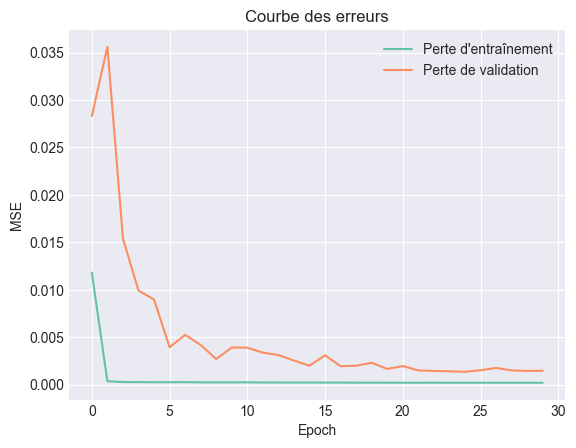

In [62]:
plt.plot(history1.history['loss'], label='Perte d\'entraînement')
plt.plot(history1.history['val_loss'], label='Perte de validation')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Courbe des erreurs')
plt.legend()
plt.grid(True)
plt.show()

##### INTERPRÉTATION

* On constate que les deux courbes décroient ensemble: on a un modèle qui **converge**
* On a pas de surapprentissage parce que la perte de validation ne croît pas pendant que la perte d'entrainement décroît. Les deux décroîent ensemmble
* à partir d'environ 20 époques, on peut déja avoir une valeur satisfaisante car, après cela, les courbes sont presque constantes , et très basses

<h4 style="color: lightblue; text-align: center"> Faisons les prédictions et l'évaluation du modèle</h4>

In [63]:
y_pred = model1.predict(X_test)
#Retour à l’échelle originale
y_test_inv = scaler.inverse_transform(y_test)
y_pred_inv = scaler.inverse_transform(y_pred)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step


##### Prédictions

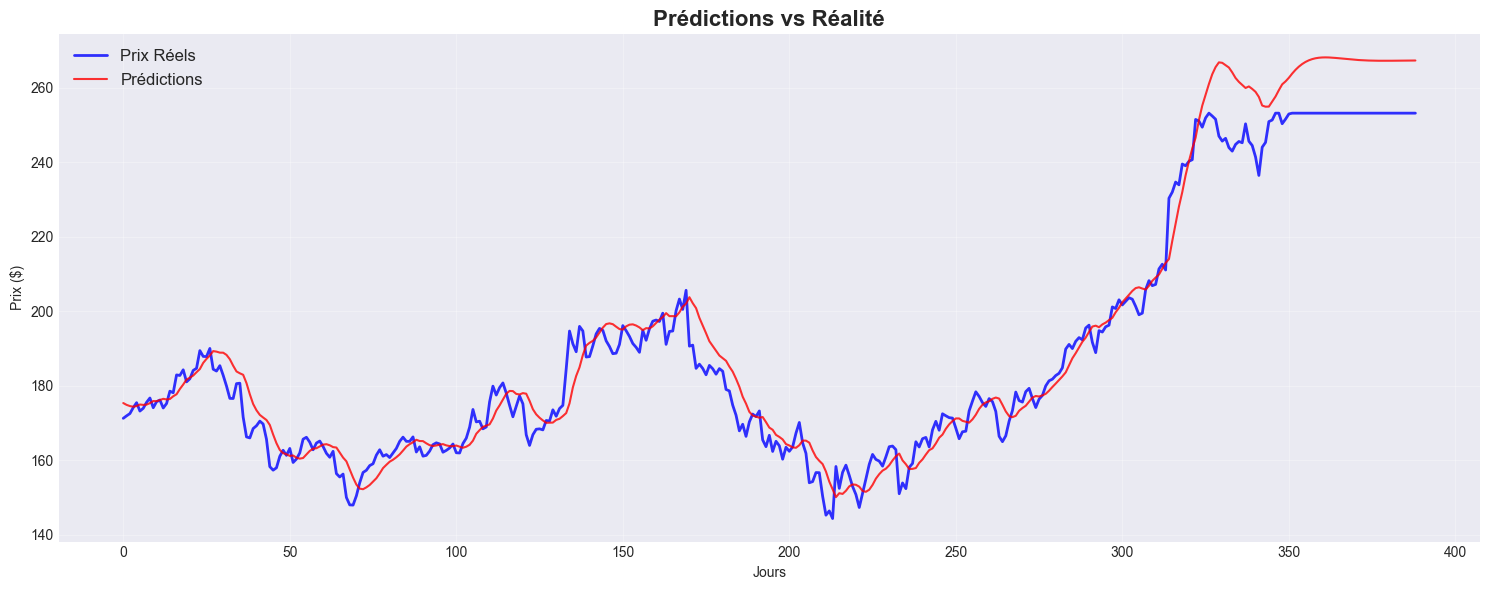

In [64]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### évaluation

In [65]:
mse1=np.mean((y_test_inv-y_pred_inv)**2)
print(f"MSE: {mse1:.4f}")
rmse1=np.sqrt(mse1)
print(f"RMSE: {rmse1:.4f}")
mae1 = mean_absolute_error(y_test_inv, y_pred_inv)
print(f"MAE : {mae1:.4f}")

MSE: 56.3078
RMSE: 7.5039
MAE : 5.6092


##### INTERPRÉTATION

* Une MAE de $\approx 5.6092$  signifie qu'en moyenne, les prédictions
   du modèle s'écartent d'environ $5.6092\$ $ des valeurs réelles: Cela montre une assez bonne performance de motre modèle.
* On voit que la courbe en rouge (prédictions) essaie de capturer au mieux la tendance des données réelles. Néanmoins, on peut constater quelques zones où les écarts entre les deux courbes sont assez grands

<h3 style="color: lightgreen; text-align: center">CONSTRUISONS UN MODÈLE LSTM AVEC PLUSIEURS COUCHES (Deep LSTM)</h3>

Un LSTM profond permet de capter des dynamiques complexes

<h4 style="color: lightblue; text-align: center">Création des couches</h4>


In [66]:
# Construction du modèle
model2 = Sequential([
    LSTM(units=64, return_sequences=False, input_shape=(X_train.shape[1], 1)),
    Dropout(0.3),
    BatchNormalization(),
    
    # Couches Dense
    Dense(units=25, activation='relu'),
    Dense(units=1)  # Sortie : prédiction du prix
])


print("ARCHITECTURE DU MODÈLE\n")
model2.summary()

ARCHITECTURE DU MODÈLE



Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,803 (73.45 KB)

 Trainable params: 18,675 (72.95 KB)

 Non-trainable params: 128 (512.00 B)

##### INTERPRÉTATION

- **LSTM(50, return_sequences=True)** : Première couche avec 50 neuronnes. `return_sequences=True` est crucial pour garantir que la sortie contienne des séquences, essentielles à l'empilement des couches LSTM.

- **Dropout(0.2)** : Le dropout permet d'éviter le surapprentissage en mettant aléatoirement à zéro **20% des unités d'entrée** à chaque mise à jour pendant l'entraînement.

- **BatchNormalization()** : La normalisation par lots stabilise le processus d'apprentissage.

- **Dense(25)** : Couche fully-connected avec 25 neurones.

- **Dense(1)** : Couche de sortie produisant la prédiction finale.

<h4 style="color: lightblue; text-align: center">Compilation du modèle</h4>

Comme dans le cas précédent, nous allons utiliser "***adam***" comme modèle d'optimisation, connu pour son adaptabilité, sa grande stabilité, et sa rapitdité de convergence.

Et aussi la fonction de perte "***MSE***",très adapté pour les tâches de regression

In [67]:
# Compilation du modèle
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, clipnorm=1.0),#Empêche l’explosion du gradient
    loss="mse",
    metrics=['mae']
)

<h4 style="color: lightblue; text-align: center"> Entrainement du modèle avec Early Stopping</h4>

Le ***Early Stopping*** arrête l'entraînement si la performance ne s'améliore plus. Il permet d'éviter le surapprentissage. Nous fixons la patiente à 10 (après 10 époques sans amélioration du modèle, celui ci s'arrête)

In [68]:
# Early Stopping : Arrête l'entraînement si la performance ne s'améliore plus
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,  # Attend 5 époques sans amélioration
    restore_best_weights=True,
    verbose=1
)

# Reduce Learning Rate : Réduit le taux d'apprentissage quand la métrique stagne
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,  # Réduit le LR de moitié
    patience=3,
    min_lr=0.00001,
    verbose=1
)

# Model Checkpoint : Sauvegarde le meilleur modèle
model_checkpoint = ModelCheckpoint(
    'best_model_aapl.h5',
    save_best_only=True,
    monitor='val_loss'
)


# Entraîner le modèle
history2 = model2.fit(
    X_train, 
    y_train,
    epochs=100,
    batch_size=25,
    validation_data=(X_test,y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)



Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - loss: 0.0911 - mae: 0.2120 - val_loss: 0.3780 - val_mae: 0.5983 - learning_rate: 5.0000e-04
Epoch 2/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 0.0269 - mae: 0.1237 - val_loss: 0.3180 - val_mae: 0.5460 - learning_rate: 5.0000e-04
Epoch 3/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0158 - mae: 0.0942 - val_loss: 0.2938 - val_mae: 0.5239 - learning_rate: 5.0000e-04
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - loss: 0.0102 - mae: 0.0768 - val_loss: 0.2358 - val_mae: 0.4675 - learning_rate: 5.0000e-04
Epoch 5/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 0.0076 - mae: 0.0665 - val_loss: 0.1973 - val_mae: 0.4272 - learning_rate: 5.0000e-04
Epoch 6/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - loss: 0.0067 - mae: 0.0613 - val_loss: 0.1675 - val_mae: 0.3937 - learning_rate: 5.0000e-04
Epoch 7/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 0.0049 - mae: 0.0545 - val_loss: 0.1279 - val_mae: 0.3437 - lear

L'entraînement est terminé.

Grâce au Early Stopping, notre modèle a arrêté l'entraînement apres **19 époque** pour éviter le surapprentissage.La meilleure époque étant la **14 iemme**

Maintenant, visualisons les courbes des erreurs mse et mae pour verifier s'il y'a cas de surapprentissage , sous apprentissage ou pas.

<h4 style="color: lightblue; text-align: center"> Visualisation des courbes des erreurs</h4>

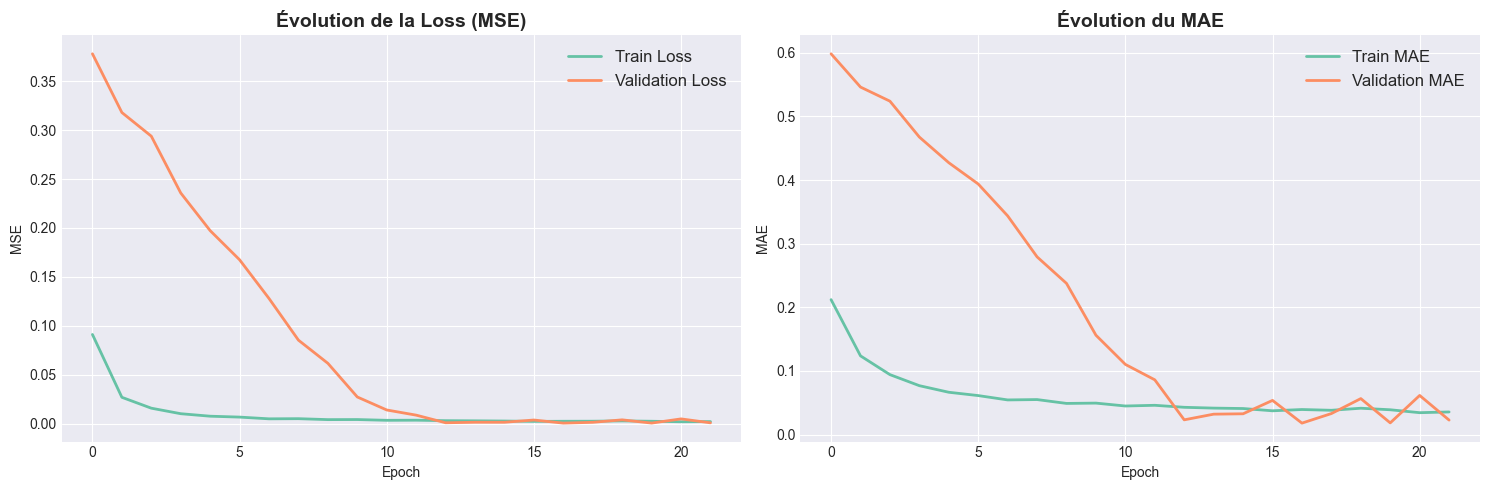

In [69]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history2.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history2.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history2.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history2.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

##### INTERPRÉTATION

Nous allons faire des interprétations par phases(époque)

* **Phase 1**: epochs  $\approx 0 \longrightarrow 10$ :</br>
Dans cette phase, on observe que:
* * Chute rapide des deux courbes dans les deux graphes
* * On peut donc dire qu'on a un très bon début, avec une convergence des deux cotés

* **Phase 2**: epochs $\approx 10 \longrightarrow 17$:</br>
Ici, on remarque que:
* * Les courbes MSE et MAE d'entrainement sont déjà très bas, il sont déjà en convergence
* * D'un autre côté, les courbes MSE et MAE de validation sont toujours en décroissance rapide. elles  présentent pics marqués dans le case de la MAE, ce qui peut signifier qu'on a une légère présence de bruit dans cette phase, mais on a toujours aucun signe de overfitting car la tendance globale reste décroissante.


* **Phase 3**(Fin de l'entraînement avec un early stopping): epochs $\approx 17 \longrightarrow 25$:</br>

* * Des deux cotés, les deux courbes atteignent un plateau très bas et train et validation sont quasi confondues: **Le modèle a atteint sa capacité optimale**


Les courbes d'apprentissage montrent une convergence stable du modèle LSTM, avec une diminution simultanée de la loss (MSE) et du MAE sur les ensembles d'entraînement et de validation. 

L'absence de divergence entre les courbes indique une bonne capacité de généralisation et l'absence de sur-apprentissage.

<h4 style="color: lightblue; text-align: center"> Faisons les prédictions et l'évaluation du modèle</h4>

In [70]:
y_pred2 = model2.predict(X_test)
#Retour à l’échelle originale
y_test_inv2 = scaler.inverse_transform(y_test)
y_pred_inv2 = scaler.inverse_transform(y_pred2)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step


##### Prédictions

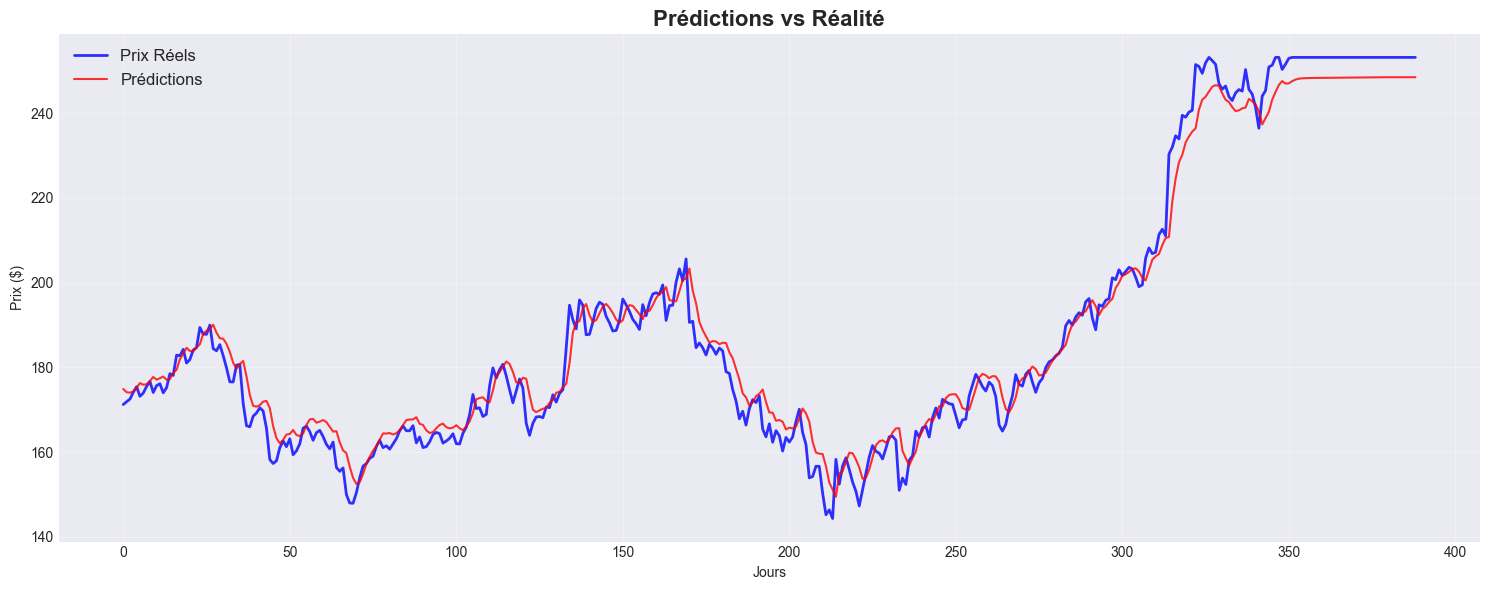

In [71]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv2, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv2, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### évaluation

In [72]:
mse=np.mean((y_test_inv2-y_pred_inv2)**2)
print(f"MSE: {mse:.4f}")
rmse=np.sqrt(mse)
print(f"RMSE: {rmse:.4f}")
mae = mean_absolute_error(y_test_inv2, y_pred_inv2)
print(f"MAE : {mae:.4f}")

MSE: 22.5145
RMSE: 4.7449
MAE : 3.6790


##### INTERPRÉTATION

* Une MAE de $\approx 3.6790$ a beaucoup diminué par rapport au modèle précédent ($mae\approx 5.6092$). Il y'a donc une amélioration dans les performances du modèle
* On a aussi une nette amélioration sur les autres métriques
* De plus, la courbe en rouge(prédiction) arrive mieux à capturer les tendances réelles par rapport à la figure précédente.
* Ce modèle est donc bein plus performant que le modèle précédent.



<h3 style="color: lightgreen; text-align: center">VALIDATION CROISÉE TEMPORELLE</h3>

Notre modèle précédent, bien que performant, peut présenter des défauts: Nous devons donc faire une ***validation croisée temporelle*** (ou *validation croisée glissante*) pour:
* **Vérifier la généralisation dans le temps**: La validation croisée temporelle (TimeSeriesSplit) permet de tester le modèle sur différentes fenêtres temporelles, garantissant qu’il apprend à généraliser dans le temps.
* **Réduire la variance de l’évaluation**: Une seule division train/test peut donner une estimation biaisée de la performance, surtout si les données ont des saisonnalités ou tendances.</br>
La validation croisée temporelle permet de calculer la performance sur plusieurs périodes, ce qui fournit une estimation plus robuste et fiable.
* **Prévenir l'overfitting**

<span style="color: orange; text-align: center">
Ici, vu qu'on travaille avec des données temporelles, on ne peut pas faire de validation croisée classique (car perte de la chronologie). C'est pour cela qu'on applique une validation croisée temporelle qui va conserver l'ordre temporelle des données, et est donc mieux adapté pour notre modèle</span>

##### Définissons la validation croisée temporelle

On utilise ``TimeSeriesSplit`` pour respecter l'ordre temporel. Chaque *fold* entraîne sur le passé et teste sur une période future.


Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 14: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 17: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 20: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 23: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 21.
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 5: early stopping
Restoring model weights from the end of the b

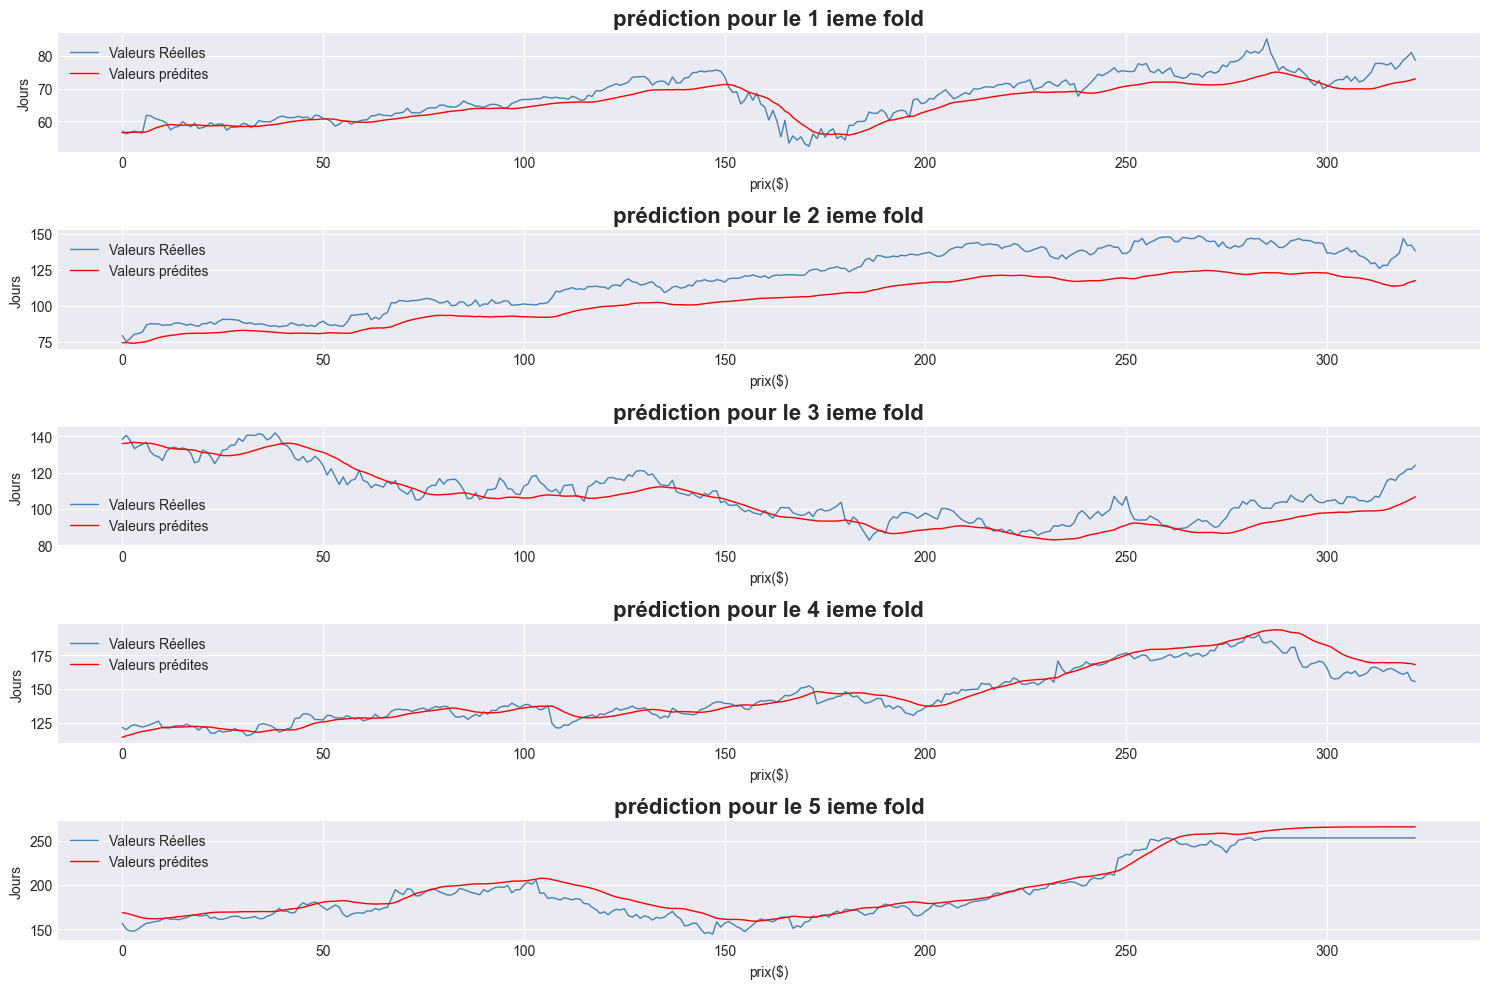

MSE par fold : [11.52326698799598, 267.8776687838843, 49.469522275055304, 36.94956103711924, 97.95324849013683]
MSE moyen : 92.75465351483832
MAE par fold : [2.729682438144743, 15.170886769014245, 5.7364649580728155, 4.402931567685154, 8.069951202109133]
MAE moyen : 7.221983387005219


In [73]:
tscv = TimeSeriesSplit(n_splits=5)  # 5 folds

mse_scores = []
mae_scores=[]
def build_model(input_shape):
        model = Sequential()
        model.add(LSTM(50, return_sequences=False, input_shape=input_shape))
        Dropout(0.3),
        model.add(Dense(25, activation='relu'))
        model.add(Dense(1))
        model.compile(optimizer='adam', loss='mse')
        return model
i=0
fig, axes = plt.subplots(5, 1, figsize=(15, 10))#pour l'affichage des 5 folds
for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model3 = build_model((X_train.shape[1], X_train.shape[2]))  # crée un nouveau modèle

    model3.fit(
        X_train, 
        y_train,
        epochs=100,
        batch_size=25,
        validation_data=(X_test, y_test),
        callbacks=[early_stopping, reduce_lr],
        verbose=0
    )
    y_pred3 = model3.predict(X_test)
    #Retour à l’échelle originale
    y_test_inv3 = scaler.inverse_transform(y_test)
    y_pred_inv3 = scaler.inverse_transform(y_pred3)
    
    mse3 = mean_squared_error(y_test_inv3, y_pred_inv3)
    mae3 = mean_absolute_error(y_test_inv3, y_pred_inv3)
    mse_scores.append(mse3)
    mae_scores.append(mae3)
    
    #visualisation pour chaque fold
    axes[i].plot(y_test_inv3, linewidth=1, color='steelblue',label='Valeurs Réelles')
    axes[i].plot(y_pred_inv3, linewidth=1, color='red',label='Valeurs prédites')
    axes[i].legend()
    axes[i].set_title(f'prédiction pour le {i+1} ieme fold', fontsize=16, fontweight='bold')
    axes[i].set_ylabel('Jours')
    axes[i].set_xlabel('prix($)')
    axes[i].grid(True)
    i=i+1
    
plt.tight_layout()
plt.show()     
print("MSE par fold :", mse_scores)
print("MSE moyen :", np.mean(mse_scores))
print("MAE par fold :", mae_scores)
print("MAE moyen :", np.mean(mae_scores))


##### Évaluation du modèle

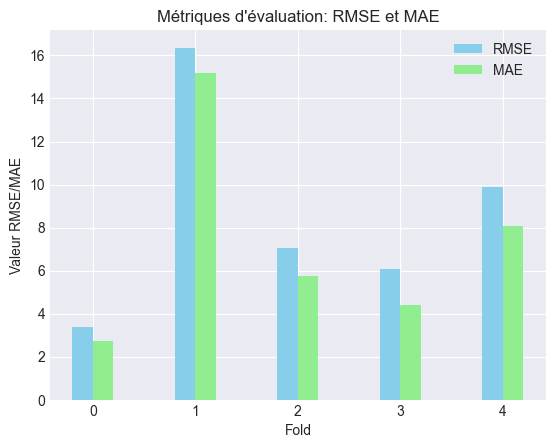

In [74]:
rmse_s=[]
for i in mse_scores :
    rmse_s.append(np.sqrt(i))
mae_s = mae_scores

indices = np.arange(len(mae_s))  # positions des groupes

largeur = 0.2  # largeur des barres

plt.bar(indices - largeur/2, rmse_s, width=largeur, color='skyblue', label='RMSE')
plt.bar(indices + largeur/2, mae_s, width=largeur, color='lightgreen', label='MAE')

plt.xlabel('Fold')
plt.ylabel('Valeur RMSE/MAE')
plt.title('Métriques d\'évaluation: RMSE et MAE')
plt.xticks(indices)
plt.legend()
plt.show()


On voit que les RMSE  et les MAE ne sont pas du tout les mêmes pour chaque fold:
* Le fold qui a la meilleure performance est le premier(rmse et mae minimal)
* Le fold qui a la beaucoup moins performant est le deuxième(rmse et mae maximal): cela peut signaler une tendance saisonière ou un changememnt dans la serie. On peut même constater l'éloignement entre la courbe des valeurs réelles et des valeurs prédites pour ce fold particulier, par rapport aux autres folds

##### Tendances moyennes et interprétations

In [75]:
print(f"Le RMSE moyen final est de :{np.mean(rmse_s)}")
print(f"Le MAE moyen final est de :{np.mean(mae_scores)}")

Le RMSE moyen final est de :8.554153675266027
Le MAE moyen final est de :7.221983387005219


On a donc les métriques de performance de notre modèle. 

Ces valeurs sont assez petites. Le modèle est donc performant

<h3 style="color: lightgreen; text-align: center">SYNTHÈSE GÉNÉRALE DES MODÈLES LSTM CLASSIQUES</h3>

* De manière générale, le modèle LSTM classique présente de très bonnes performances, avec des erreurs très faibles.
* On a fait deux modèles LSTM classiques : l'un avec une seule coucle et l'autre avec plusieurs couches. En comparant ces deux modèles, on a constater que le modèle LSTM multi couche avait de meilleures performances que celui avec une seule couche.
* Puis, nous avons fait une validation croisée, pour une généralisation dans le temps de notre modèle et en étudiant les performances, on constate que ce dernier est toujours performant.
* La validation croisée est donc une étape très importante lorsqu'on éffectue une modélisation LSTM classique


<h2 style="color: cyan; text-align: center">PRÉDICTION DES TENDANCES BOURSIÈRES AVEC UN LSTM AVEC MÉCANISME D'ATTENTION</h2>

Un LSTM standard traite la séquence et condense toute l'information dans le dernier état caché, ce qui peut perdre certaines informations importantes.

Le **mécanisme d'attention** permet de pondérer chaque étape de la séquence en fonction de son importance pour la prédiction finale.

Cela améliore souvent la performance sur des séries temporelles longues ou complexes.


Chaque état caché du LSTM reçoit un *poids d'importance*. Les états les plus informatifs contribuent davantage à la prédiction finale

<h3 style="color: lightgreen; text-align: center"> IMPLÉMENTATION D'UNE COUCHE D'ATTENTION</h3>

In [76]:
# Définir un petit module Attention
class Attention(Layer):
    def __init__(self, **kwargs):
        super(Attention, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name='attention_weight',
                                 shape=(input_shape[-1], 1),
                                 initializer='random_normal',
                                 trainable=True)
        self.b = self.add_weight(name='attention_bias',
                                 shape=(input_shape[1], 1),
                                 initializer='zeros',
                                 trainable=True)
        super(Attention, self).build(input_shape)

    def call(self, x):
        # Score = tanh(W*h + b)
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        # Alpha = softmax(score)
        alpha = tf.keras.backend.softmax(e, axis=1)
        # Contexte = somme pondérée
        context = x * alpha
        context = tf.keras.backend.sum(context, axis=1)
        return context


<h3 style="color: lightgreen; text-align: center">CONSTRUCTION DU MODÈLE LSTM AVEC ATTENTION (1 couche)</h3>

Nous allons d'abord faire un modèle simple à une couche , avec mécanisme d'attente

In [77]:
# Construction du modèle
inputs = Input(shape=(time_steps, 1))
lstm_out = LSTM(50, return_sequences=True)(inputs)
attention_out = Attention()(lstm_out)
dense1 = Dense(25, activation='relu')(attention_out)
output = Dense(1)(dense1)

model_attention = Model(inputs=inputs, outputs=output)
model_attention.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_attention.summary()

Model: "functional_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_6 (Attention)         │ (None, 50)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,811 (46.14 KB)

 Trainable params: 11,811 (46.14 KB)

 Non-trainable params: 0 (0.00 B)

##### Entraînement du modèle

In [78]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

history_attention = model_attention.fit(
    X, y,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping,reduce_lr],
    verbose=1
)


Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - loss: 0.0131 - mae: 0.0746 - val_loss: 0.0099 - val_mae: 0.0825 - learning_rate: 0.0010
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0014 - mae: 0.0286 - val_loss: 0.0083 - val_mae: 0.0739 - learning_rate: 0.0010
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0015 - mae: 0.0300
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0014 - mae: 0.0284 - val_loss: 0.0076 - val_mae: 0.0692 - learning_rate: 0.0010
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0013 - mae: 0.0274 - val_loss: 0.0075 - val_mae: 0.0695 - learning_rate: 5.0000e-04
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0013 - mae: 0.0273 - val_loss: 0.0072 - val_mae: 0.0670 - learning_rate: 5.0000e-04
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0013 - mae: 0.0270
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0

Nous avons donc entrìner sur 22 époques, pour un nombre  d'époque optimale de 12

##### Visualisation des courbes d'erreur

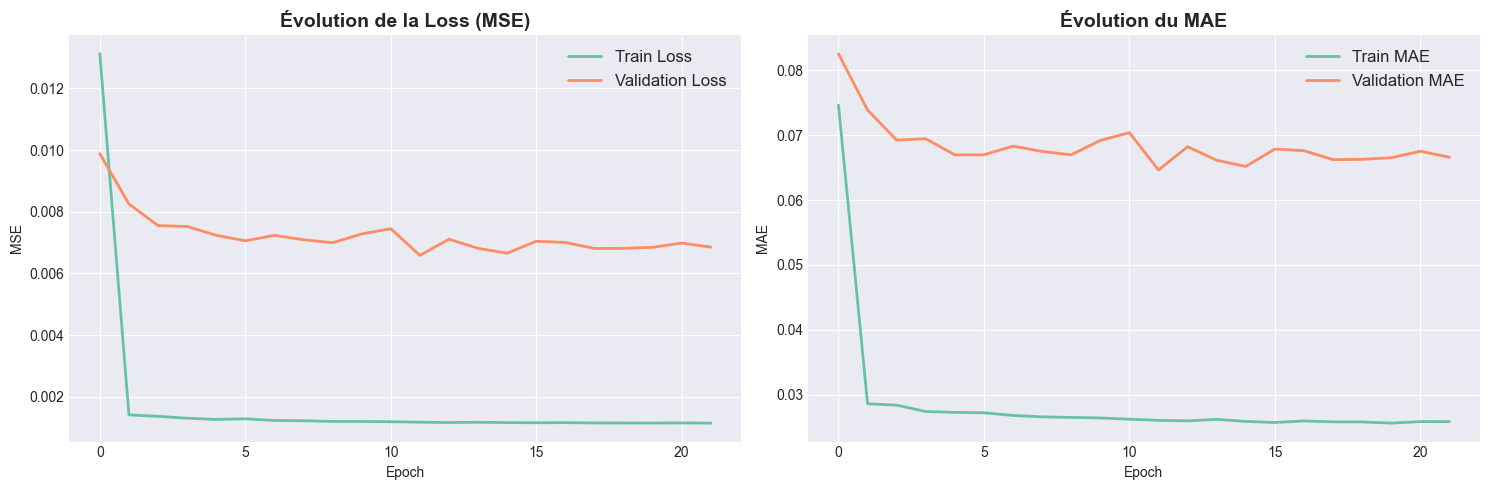

In [79]:

# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history_attention.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_attention.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history_attention.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history_attention.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

##### Interprétation
* 'dans un premier temps,on a une chutte rapide des courbes d'entraînement (MSE et MAE). Puis, ces dernières sont presque constantes après avoir atteint de bas. Elles décroîent très lentement.
* Pour les courbes de validation, on a une légère cchutte au début, suivie par une peite phase d'une légère décroissance, et après, des deux graphes, et à la même période, on constate un pic(epoch 10) suivie par une phase pratiquement stable.
* Dans l'ensemble, les courbes sont décroissante, bien que très légèrement au point de pouvoir être dites constantes: Ceci nous montre que le modèle, bien que pas très performant, n'a pas de sur-apprentissage

##### Prédictions

In [80]:
y_pred_att = model_attention.predict(X_test)
#Retour à l’échelle originale
y_test_inv_att = scaler.inverse_transform(y_test)
y_pred_inv_att = scaler.inverse_transform(y_pred_att)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step


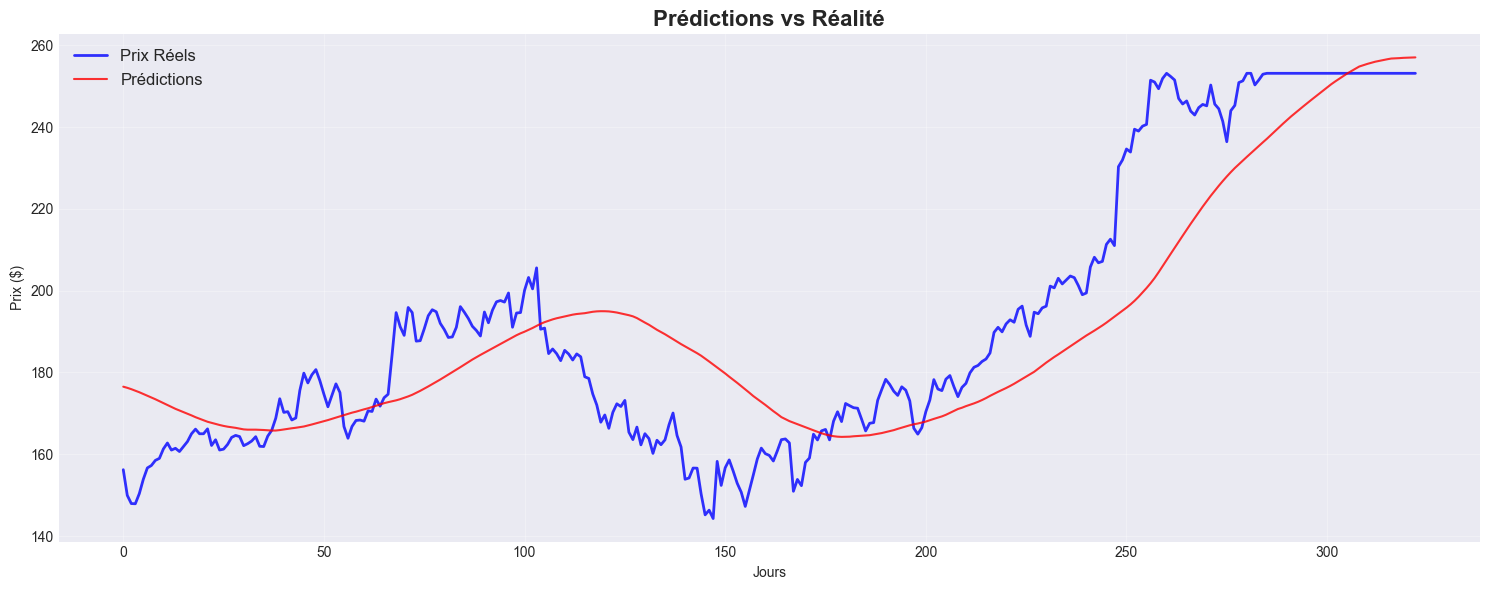

In [81]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_att, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_att, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### Évaluation

In [82]:
mse1=np.mean((y_test_inv_att-y_pred_inv_att)**2)
print(f"MSE: {mse1:.4f}")
rmse1=np.sqrt(mse1)
print(f"RMSE: {rmse1:.4f}")
mae1 = mean_absolute_error(y_test_inv_att, y_pred_inv_att)
print(f"MAE : {mae1:.4f}")

MSE: 294.8833
RMSE: 17.1722
MAE : 13.4823


##### Interprétation

On peut clairement constater que ce modèle est tellement moins performant par rapport aux modèles précédents. Essayons cette fois ci de faire un mécanisme d'attention plusieurs couches pour voire la différence

<h3 style="color: lightgreen; text-align: center">CONSTRUCTION DU MODÈLE LSTM MULTI-COUCHE(Deep)</h3>

In [83]:
model_deep = Sequential()
model_deep.add(LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model_deep.add(Dropout(0.3))
model_deep.add(LSTM(64, return_sequences=True))
model_deep.add(Dropout(0.2))
model_deep.add(Attention())
model_deep.add(Dense(1))
model_deep.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_deep.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 60, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_7 (Attention)         │ (None, 64)             │           124 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,109 (195.74 KB)

 Trainable params: 50,109 (195.74 KB)

 Non-trainable params: 0 (0.00 B)

##### Entraînement du modèle

In [84]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

history_deep = model_deep.fit(
    X, y,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 13s 120ms/step - loss: 0.0074 - mae: 0.0571 - val_loss: 0.0102 - val_mae: 0.0835
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - loss: 0.0015 - mae: 0.0295 - val_loss: 0.0087 - val_mae: 0.0754
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - loss: 0.0015 - mae: 0.0290 - val_loss: 0.0091 - val_mae: 0.0781
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - loss: 0.0015 - mae: 0.0293 - val_loss: 0.0124 - val_mae: 0.0924
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - loss: 0.0014 - mae: 0.0286 - val_loss: 0.0131 - val_mae: 0.0949
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - loss: 0.0014 - mae: 0.0286 - val_loss: 0.0080 - val_mae: 0.0726
Epoch 7/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - loss: 0.0013 - mae: 0.0276 - val_loss: 0.0081 - val_mae: 0.0737
Epoch 8/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.0014 - mae: 0.0285 - val_loss: 0.0085 - val_mae: 0.0759
Epoch 9/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step 

Ici le early stopping nous arrête à la 19 ieme époque 

##### Visualisation des courbes d'erreur

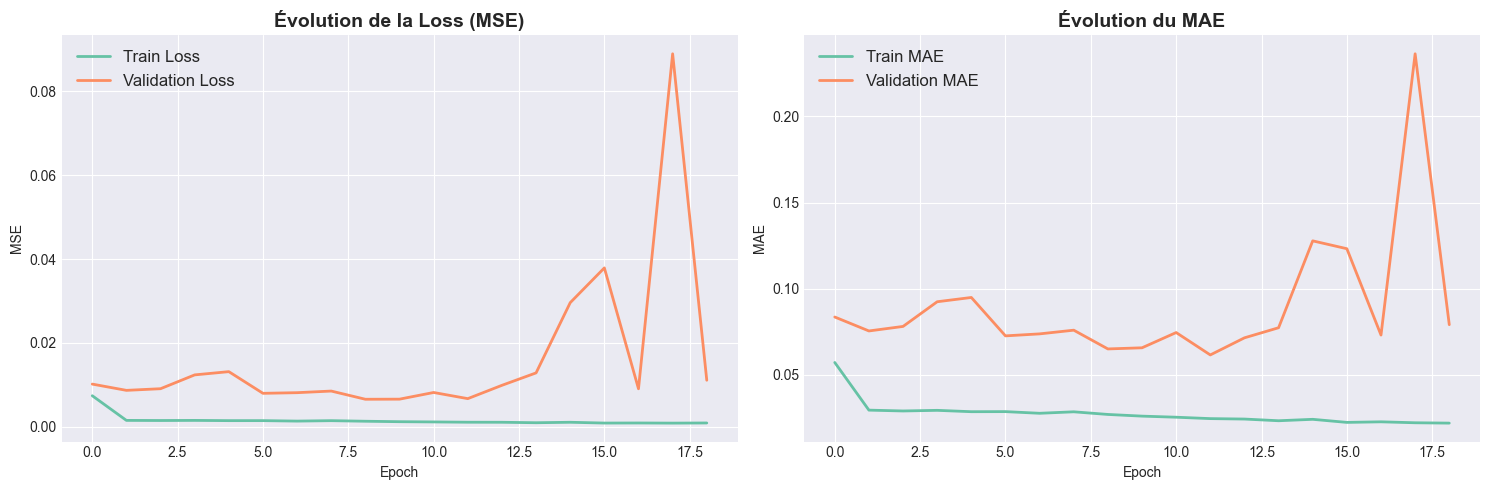

In [85]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# MSE
axes[0].plot(history_deep.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_deep.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Évolution de la Loss (MSE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=12)
axes[0].grid(True)

# MAE
axes[1].plot(history_deep.history['mae'], label='Train MAE', linewidth=2)
axes[1].plot(history_deep.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Évolution du MAE', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend(fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()

##### Interprétation
* La courbe des erreurs d'entraînement est très bas, mais, celle de validation est très instable des deux cotés. On a de grande variation , et de manière générale, les courbes d'erreur de validation sont en croissance
* Néanmoins, autour de l'époch optimal, on a une  minimisation les erreurs de validation. Ce qui montre qu'on a de bonne performances à cette époch
* On peut donc dire que, de manière générale, ce modèle (**LSTM Mécanisme d'attention multi-couche**) n'est pas très adapté pour notre base de données. 

##### Prédictions

In [86]:
y_pred_deep = model_attention.predict(X_test)
#Retour à l’échelle originale
y_test_inv_deep = scaler.inverse_transform(y_test)
y_pred_inv_deep = scaler.inverse_transform(y_pred_deep)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


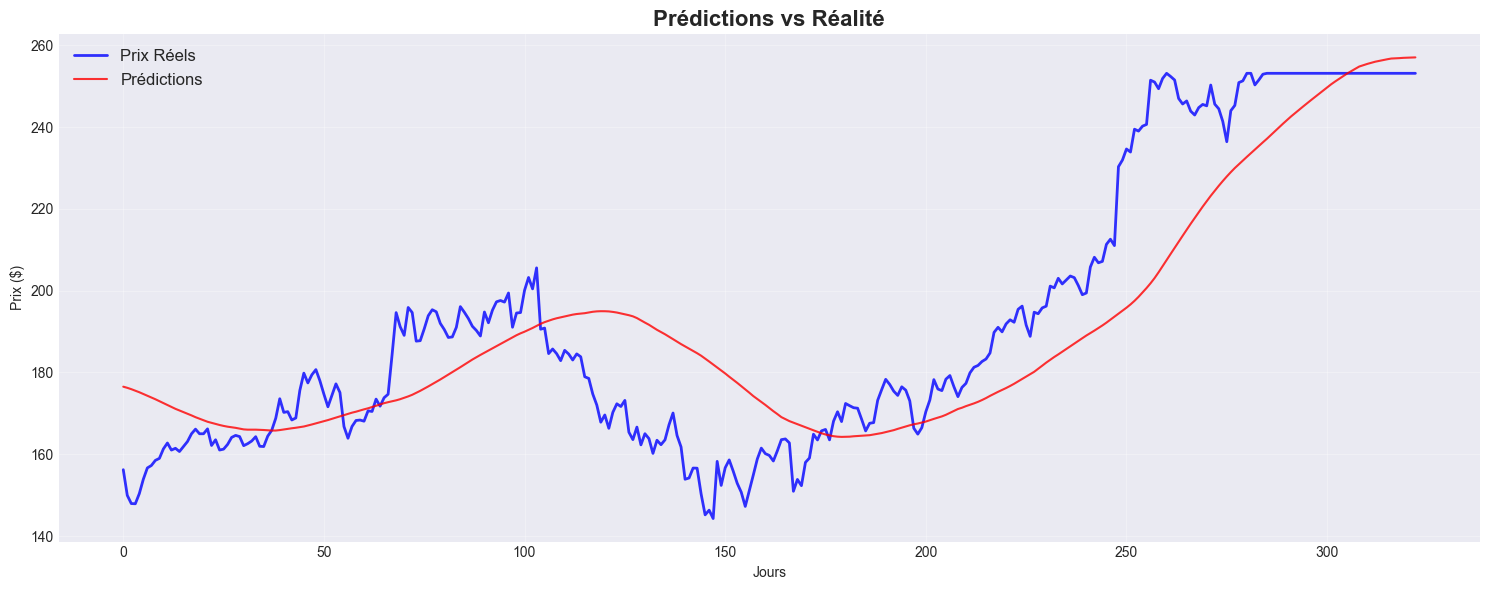

In [87]:
# Graphique : Prédictions vs Réalité
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv_deep, label='Prix Réels', linewidth=2, alpha=0.8, color='blue')
plt.plot(y_pred_inv_deep, label='Prédictions', linewidth=1.5, alpha=0.8, color='red')
plt.title('Prédictions vs Réalité', fontsize=16, fontweight='bold')
plt.xlabel('Jours')
plt.ylabel('Prix ($)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### Évaluation

In [88]:
mse1=np.mean((y_test_inv_deep-y_pred_inv_deep)**2)
print(f"MSE: {mse1:.4f}")
rmse1=np.sqrt(mse1)
print(f"RMSE: {rmse1:.4f}")
mae1 = mean_absolute_error(y_test_inv_deep, y_pred_inv_deep)
print(f"MAE : {mae1:.4f}")

MSE: 294.8833
RMSE: 17.1722
MAE : 13.4823


##### Interprétation

* On constate qu'on a très peu d'amélioration par rapport au modèle simple précédent: On peut donc dire que, dans le cas de notre base de données, on a pas necessairement besoin de plusieurs couches pour faire un modèle LSTM avec mécanisme d'attention

<h4 style="color: lightgreen; text-align: center">VALIDATION CROISÉE TEMPORELLE</h4>

Dans le cadre du modèle LSTM avec mécanisme d'attention, nous effectuons aussi une validation croisée

##### Construction du modèle


Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 12: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 15: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 18: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 21: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 12.
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 12: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 15: ReduceLROnPlateau reducing le

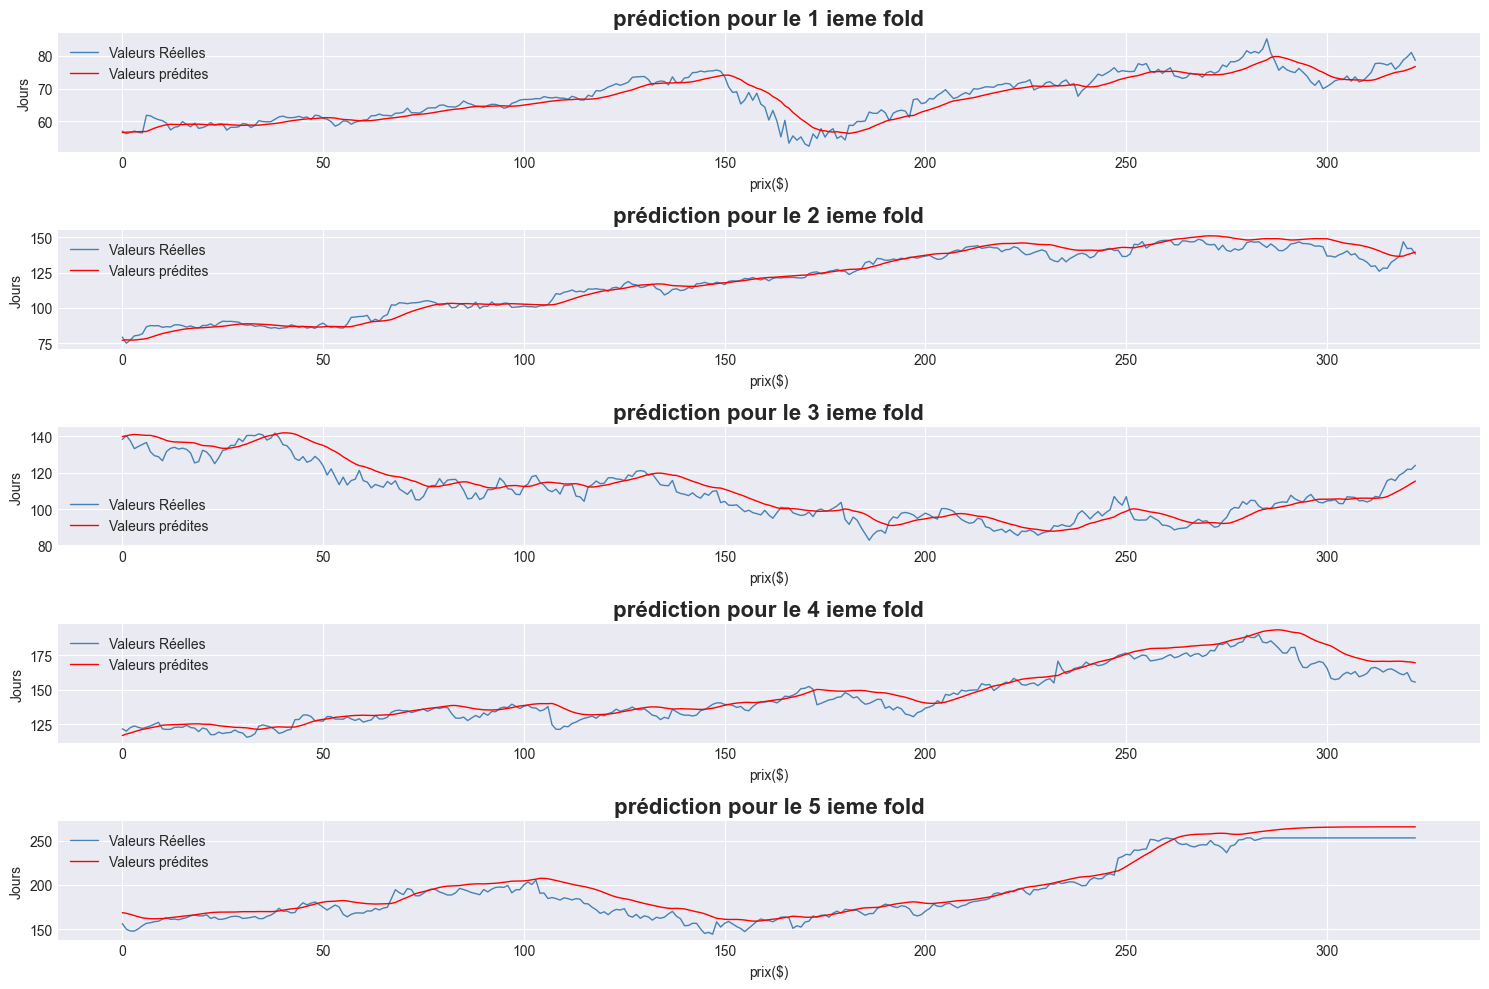

MSE par fold : [6.8429142352028345, 18.912727515816712, 31.3913767259972, 43.33792239344959, 97.95324849013683]
MSE moyen : 39.68763787212063
MAE par fold : [1.974641711350196, 3.1998461791236332, 4.509865704704733, 4.751915568537757, 8.069951202109133]
MAE moyen : 4.50124407316509


In [89]:
tscv = TimeSeriesSplit(n_splits=5)  # 5 folds

mse_scores1 = []
mae_scores1=[]
def build_model(input_shape):
        model = Sequential()
        model.add(LSTM(50, return_sequences=True, input_shape=input_shape))
        model.add(Dropout(0.3)),
        model.add(LSTM(64, return_sequences=True))
        model.add(Dropout(0.2))
        model.add(Attention())
        model.add(Dense(1))
        model.compile(optimizer='adam', loss='mse', metrics=['mae'])
        return model
    
i=0
fig, axes = plt.subplots(5, 1, figsize=(15, 10))#pour l'affichage des 5 folds
for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model4 = build_model((X_train.shape[1], X_train.shape[2]))  # crée un nouveau modèle

    model4.fit(
        X_train, 
        y_train,
        epochs=100,
        batch_size=25,
        validation_data=(X_test, y_test),
        callbacks=[early_stopping, reduce_lr],
        verbose=0
    )
    y_pred4 = model3.predict(X_test)
    #Retour à l’échelle originale
    y_test_inv4 = scaler.inverse_transform(y_test)
    y_pred_inv4 = scaler.inverse_transform(y_pred4)
    
    mse4 = mean_squared_error(y_test_inv4, y_pred_inv4)
    mae4 = mean_absolute_error(y_test_inv4, y_pred_inv4)
    mse_scores1.append(mse4)
    mae_scores1.append(mae4)
    
    #visualisation pour chaque fold
    axes[i].plot(y_test_inv4, linewidth=1, color='steelblue',label='Valeurs Réelles')
    axes[i].plot(y_pred_inv4, linewidth=1, color='red',label='Valeurs prédites')
    axes[i].legend()
    axes[i].set_title(f'prédiction pour le {i+1} ieme fold', fontsize=16, fontweight='bold')
    axes[i].set_ylabel('Jours')
    axes[i].set_xlabel('prix($)')
    axes[i].grid(True)
    i=i+1
    
plt.tight_layout()
plt.show()     
print("MSE par fold :", mse_scores1)
print("MSE moyen :", np.mean(mse_scores1))
print("MAE par fold :", mae_scores1)
print("MAE moyen :", np.mean(mae_scores1))


##### Évaluation du modèle

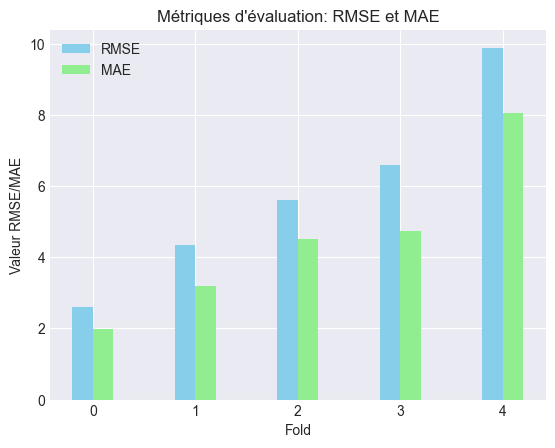

In [90]:
rmse_s1=[]
for i in mse_scores1 :
    rmse_s1.append(np.sqrt(i))
mae_s1 = mae_scores1

indices = np.arange(len(mae_s1))  # positions des groupes

largeur = 0.2  # largeur des barres

plt.bar(indices - largeur/2, rmse_s1, width=largeur, color='skyblue', label='RMSE')
plt.bar(indices + largeur/2, mae_s1, width=largeur, color='lightgreen', label='MAE')

plt.xlabel('Fold')
plt.ylabel('Valeur RMSE/MAE')
plt.title('Métriques d\'évaluation: RMSE et MAE')
plt.xticks(indices)
plt.legend()
plt.show()


##### Tendances moyennes et interprétation

In [91]:
print(f"Le RMSE moyen final est de :{np.mean(rmse_s1)}")
print(f"Le MAE moyen final est de :{np.mean(mae_scores1)}")

Le RMSE moyen final est de :5.809572322313219
Le MAE moyen final est de :4.50124407316509


La validation croisée nous présente des métriques bien plus satisfaisantes que précédament. Il généralise bien le modèle dans le temps, et évite l'overfitting. La validation croisée est donc une bonne méthode d'optmisation dans notre cas

<h3 style="color: lightgreen; text-align: center">SYNTHÈSE GÉNÉRALE DES MODÈLES LSTM AVEC MÉCANISME D'ATTENTION</h3>

* De manière générale, le modèle LSTM avec mécanisme d'attention avec une seule couche comme avec plusieurs couches présente plus ou moins les mêmes performances.

* On a fait une validation croisée sur le modèle et on a obtenu de meilleures performances. La validation croisée est donc une très bonne méthode pour optimiser un modèle.


<h2 style="color: cyan; text-align: center">SYNTHÈSE GÉNÉRALE DES MODÈLES LSTM : CLASSIQUE ET MÉCANISME D'ATTENTION</h2>

##### LSTM CLASSIQUE

* Ce modèle a particulièrement été performant pour notre base de données

* Le modèle LSTM simple parvient à capter la dynamique générale de la série temporelle, notamment les tendances locales et les variations à court terme. Il résout partiellement le problème du vanishing gradient, et exploite l'information passée via sa mémoire interne pour faire des prédictions

* Néanmoins, ce modèle peut présenter des défauts. Le LSTM repose essentiellement sur le dernier état caché pour effectuer la prédiction, ce qui peut conduire à une perte d’information lorsque certaines observations passées sont plus pertinentes que d’autres.


##### LSTM AVEC MÉCANISME D'ATTENTION

* L’introduction du mécanisme d’attention permet au modèle d’attribuer des poids différenciés aux différentes observations passées, renforçant ainsi la prise en compte des périodes les plus informatives.

* Le modèle Attention-LSTM présente une meilleure capacité à reproduire les variations locales de la série, en particulier lors des périodes de forte instabilité.

* Néanmoins, ce modèle n'a pas été très performant pour cette base de données comparé au modèles LSTM

# CONCLUSION PARTIELLE
Dans notre projet, aprÈs avoir fait une analyse et un nettoyage de notre base de données, nous avons fait plusieurs modèles notamen: LSTM et RNN, uni-couche et multi-couche chacun , puis LSTM et RNN chacun avec mécanisme d'attention. Nous avons aussi fait des validations croisés pour chacun des modèles cité plus haut.

Pour conclure, on dira que le modèle le plus performant est le LSTM classique avec plusieurs couches. Ce modèle s'est avéré être le plus performant parmis tous les modèles jusqu'ici présenté. C'est donc ce modèle qui va être déployé dans la suite

<div style="background-color:orange"><h1 style="color:black;text-align:center">DÉPLOIEMENT DE NOTRE MODÈLE OPTIMAL: LSTM CLASSIQUE MULTI-COUCHES</h1></div>

<h2 style="color:cyan; text-align:center">Sauvegarde de notre modèle optimal: LSTM classique multi-couches</h2>

In [100]:

model2.save("lstm_multicouche_close.keras")

joblib.dump(scaler, "scaler_close.pkl")#sauvegarde de scaler
params = {  #sauvegarde des paramètres
    "time_steps": time_steps
}
with open("params.json", "w") as f:
    json.dump(params, f)
    
    

<h2 style="color:cyan; text-align:center">Déploiement du modèle</h2>

In [104]:
%%writefile app.py

from flask import Flask, request, jsonify
import numpy as np
import joblib
import json
from tensorflow.keras.models import load_model

model = load_model("lstm_multicouche_close.keras")
scaler = joblib.load("scaler_close.pkl")

with open("params.json") as f:
    params = json.load(f)

TIME_STEPS = params["time_steps"]

app = Flask(__name__)

@app.route("/predict", methods=["POST"])
def predict():
    data = request.get_json()
    closes = np.array(data["last_closes"], dtype=float)

    closes_scaled = scaler.transform(closes.reshape(-1, 1))
    X_input = closes_scaled[-TIME_STEPS:].reshape(1, TIME_STEPS, 1)

    pred = scaler.inverse_transform(model.predict(X_input))

    return jsonify({"predicted_close": float(pred[0][0])})

if __name__ == "__main__":
    app.run(debug=True)


Writing app.py


In [ ]:
!python app.py


<div style="background-color:lightblue"><h1 style="color:black;text-align:center">CONCLUSION GÉNÉRALE</h1></div>


Au terme de ce travail, l'objectif principal était de concevoir, entraîner et évaluer des modèles de deep learning afin de résoudre un problème de prédiction à partir de données réelles.

À travers les différentes étapes, allant de la préparation des données, au choix de l'architecture du réseau de neurones, jusqu'à l'analyse des performances , nous avons pu mettre en évidence l'apport des modèles profonds dans la modélisation de relations complexes et non linéaires.

Les résultats obtenus montrent que les architectures utilisés, notamment les réseaux de neurones profonds tels que les modèles LSTM/RNN + validation croisée et avec ou sans mécanisme d'attention, sont capables de capturer efficacement les dynamiques sous-jacentes des données étudiées. 

L'analyse des courbes d'apprentissage et des métriques de performance a permis d'évaluer la qualité de l'apprentissage, de détecter les phénomènes de surapprentissage ou de sous-apprentissage, et d'ajuster les hyperparamètres afin d'améliorer la généralisation du modèle.

Nous avons pu en ressortir le modèle optimal (Ici le modèle LSTM avec plusieurs couches), et nous l'avons déployé, pour des utilisations futures


En conclusion, ce projet a permis de consolider les connaissances théoriques en apprentissage profond tout en développant des compétences pratiques en implémentation, en analyse critique des résultats et en interprétation des performances des modèles. Il constitue ainsi une base solide pour des travaux futurs plus approfondis dans le domaine du deep learning et de ses applications.